## 09. Climate-ESG Risk Intelligence: Feature Engineering and Feed-Forward Neural Network (PyTorch) 

**Project Title**

**AI-Powered Climate & ESG Risk Intelligence Platform for Multi-Sector Decision Support in Germany**


| **Project Information** |                                                                                                                                                          |
| ----------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Project Title**       | **AI-Powered Climate & ESG Risk Intelligence Platform for Multi-Sector Decision Support in Germany**                                                     |
| **Case Organization**   | **KlimaIQ Analytics GmbH** *(Fictional Industry Case Study)*                                                                                             |
| **Author**              | **Purity Mbaabu**                                                                                                                                        |
| **Role (Case Study)**   | Full-Stack AI Engineer, KlimaIQ Analytics GmbH                                                                                                       |
| **Program**             | AI Engineering – Digethic Business School, Germany                                                                                                  |
| **Project Date**        | July 2026                                                                                                                                          |
| **Study Area**          | Germany (400 Districts / Project400 Framework)                                                                                                       |
| **Study Period (Data)** | 1990–2025                                                                                                                                           
| **Dataset**             | Integrated Climate-ESG Master Dataset (14,400 observations)                                                                                                     |
| **Model**               | Feed-Forward Neural Network (PyTorch)                                                                                                                |
| **Objective**           | Design, train, evaluate, and explain a prototype Feed-Forward Neural Network (FFNN) for district-level Climate & ESG Risk Index prediction. |
| **Solution Type**       | Prototype AI-Powered Climate & ESG Decision-Support System |



### Overview

This notebook develops the machine learning pipeline for the Climate-ESG Risk Intelligence Germany project. Using the integrated master dataset produced in Notebook 08, it performs data validation, feature engineering, target variable construction, neural network development, model evaluation, and explainability.

The objective is to develop a Feed-Forward Neural Network (FFNN) capable of learning relationships between regional climate hazards and socioeconomic indicators to estimate district-level climate risk across Germany's 400 districts.

**Data Inputs**

This notebook uses the integrated master dataset created during the harmonization phase:

- Climate-ESG master dataset (1990–2025)
- 400 German districts (Project400 administrative framework)
- 36-year time series (1990–2025)

The Climate-ESG master dataset (1990–2025) is constructed from five feature datasets as below:

##### Three climate hazard indicators:
- Heatwave Days
- Flood Proxy (Rx5day)
- Meteorological Drought Magnitude

##### Two socioeconomic indicators:
- GDP per capita
- Unemployment rate

**Dataset characteristics:**

- Districts: 400
- Years: 1990–2025
- Total observations: 14,400

**Objective**

| **Objective** | Develop, train, evaluate, and explain a prototype Feed-Forward Neural Network (FFNN) for district-level Climate & ESG Risk Index prediction. |

**Specifically, this notebook:**

1. validates the integrated master dataset;
2. engineers machine learning features;
3. constructs the Climate Risk Index target variable;
4. partitions the data into training, validation, and testing sets;
5. scales predictor variables;
6. develops and trains a PyTorch Feed-Forward Neural Network;
7. evaluates predictive performance using regression metrics;
8. interprets model behaviour using SHAP explainability; and
9. exports the trained model and preprocessing objects for deployment.

**Why this step?**

Notebook 08 completed the data engineering phase by integrating harmonized climate and socioeconomic datasets into a unified district-level master dataset.

This notebook transitions from data engineering to machine learning, transforming the harmonized data into predictive intelligence. The resulting FFNN provides a prototype AI model capable of learning nonlinear relationships between climate hazards and socioeconomic conditions that contribute to regional climate risk.

**Workflow**

1. Load the Climate-ESG master dataset.
2. Validate data quality and completeness.
3. Perform feature engineering.
4. Construct the Climate Risk Index target variable.
5. Split data into training, validation, and testing datasets.
6. Standardize predictor variables.
7. Develop the Feed-Forward Neural Network (PyTorch).
8. Train the neural network.
9. Evaluate model performance.
10. Interpret predictions using SHAP.
11. Export the trained model and preprocessing pipeline.

**Outputs**

- Validated Climate-ESG master dataset
- Engineered feature matrix
- Climate Risk Index target variable
- Trained Feed-Forward Neural Network
- Feature scaler
- SHAP explainability outputs
- Saved model ready for deployment

**Next Phase**

The trained neural network produced in this notebook will support the deployment stage of the project, where the model will be integrated into a Flask REST API and connected to a lightweight frontend for interactive district-level climate risk assessment.

### Import Required Libraries

In [1]:
# ============================================================
# Import Libraries
# ============================================================

# General
from pathlib import Path
import joblib
import warnings

# Data handling
import numpy as np
import pandas as pd
from itertools import combinations

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# Deep Learning
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Explainability
import shap

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully.")

print("=" * 60)
print("Environment")
print("=" * 60)
print(f"Pandas : {pd.__version__}")
print(f"NumPy  : {np.__version__}")
print(f"PyTorch: {torch.__version__}")
print("=" * 60)

Libraries imported successfully.
Environment
Pandas : 2.3.3
NumPy  : 2.3.4
PyTorch: 2.10.0+cpu


### Define Project Configuration

In [2]:
# ============================================================
# Project directories
# ============================================================

PROJECT_ROOT = Path.cwd().parent

MASTER_DATA = PROJECT_ROOT / "data" / "processed" / "master" / "master_dataset_1990_2025.csv"

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("Project Paths")
print("=" * 60)
print(f"Project Root : {PROJECT_ROOT}")
print(f"Master Data  : {MASTER_DATA}")
print(f"Model Folder : {MODEL_DIR}")
print(f"Figures      : {FIGURE_DIR}")
print("=" * 60)

assert MASTER_DATA.exists(), "Master dataset not found."
print("✓ Master dataset located successfully.")
print("✓ Master dataset located successfully.")

Project Paths
Project Root : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany
Master Data  : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\processed\master\master_dataset_1990_2025.csv
Model Folder : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\models
Figures      : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\reports\figures
✓ Master dataset located successfully.
✓ Master dataset located successfully.


### Load Master Dataset

In [3]:
# ============================================================
# Step 2: Load Master Dataset
# ============================================================

# Load integrated master dataset
df = pd.read_csv(MASTER_DATA)

# Basic dataset information
n_rows, n_cols = df.shape
n_districts = df["district_code"].nunique()
n_years = df["year"].nunique()
min_year = df["year"].min()
max_year = df["year"].max()
expected_rows = 400 * 36

print("=" * 60)
print("Master Dataset Loaded")
print("=" * 60)
print(f"Rows          : {n_rows:,}")
print(f"Columns       : {n_cols}")
print(f"Districts     : {n_districts}")
print(f"Years         : {min_year}–{max_year} ({n_years} years)")
print(f"Expected rows : {expected_rows:,}")
print(f"Memory usage  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print("=" * 60)

# Validation checks
assert n_rows == expected_rows, "Unexpected number of rows."
assert n_districts == 400, "Unexpected number of districts."
assert n_years == 36, "Unexpected number of years."

print("✓ Master dataset loaded successfully.")
print("✓ Dataset dimensions match expected Project400 × 1990–2025 panel structure.")

# Display first records
df.head()

Master Dataset Loaded
Rows          : 14,400
Columns       : 8
Districts     : 400
Years         : 1990–2025 (36 years)
Expected rows : 14,400
Memory usage  : 2.34 MB
✓ Master dataset loaded successfully.
✓ Dataset dimensions match expected Project400 × 1990–2025 panel structure.


,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.1,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.1,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.1,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.1,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.1,8.16


In [4]:
print(df[["gdp_per_capita", "unemployment_rate"]].isna().sum())

gdp_per_capita       3996
unemployment_rate    3996
dtype: int64


In [5]:
# Districts with missing GDP values

missing_districts = (
    df[df["gdp_per_capita"].isna()]
    .groupby(["district_code", "district_name"])
    .size()
    .reset_index(name="missing_records")
)

print(f"Districts affected: {len(missing_districts)}")
display(missing_districts.head(20))

Districts affected: 111


,district_code,district_name,missing_records
0,DE118,"Heilbronn, Landkreis",36
1,DE123,"Karlsruhe, Landkreis",36
2,DE142,"Tübingen, Landkreis",36
3,DE211,"Ingolstadt, Kreisfreie Stadt",36
4,DE212,"München, Kreisfreie Stadt",36
5,DE213,"Rosenheim, Kreisfreie Stadt",36
6,DE21H,"München, Landkreis",36
7,DE21K,"Rosenheim, Landkreis",36
8,DE221,"Landshut, Kreisfreie Stadt",36
9,DE222,"Passau, Kreisfreie Stadt",36


In [6]:
print(df[df["gdp_per_capita"].isna()].year.unique())

[1990 1991 1992 1993 1994 1995 1996 1997 1998 1999 2000 2001 2002 2003
 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017
 2018 2019 2020 2021 2022 2023 2024 2025]


### Dataset Validation & Quality Checks

In [7]:
# ============================================================
# Step 3: Dataset Validation & Quality Checks
# Dataset structure and data types
# ============================================================

print("=" * 60)
print("Dataset Structure & Data Types")
print("=" * 60)

# Basic structure
print(f"Dataset shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory usage  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nColumn names:")
for col in df.columns:
    print(f" - {col}")

print("\nData types:")
print(df.dtypes)

# Expected schema
expected_columns = [
    "district_code",
    "district_name",
    "year",
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate",
]

missing_columns = [col for col in expected_columns if col not in df.columns]
extra_columns = [col for col in df.columns if col not in expected_columns]

print("\nSchema validation:")
print(f"Expected columns : {len(expected_columns)}")
print(f"Observed columns : {df.shape[1]}")
print(f"Missing columns  : {missing_columns if missing_columns else 'None'}")
print(f"Extra columns    : {extra_columns if extra_columns else 'None'}")

# Data type groups
identifier_cols = ["district_code", "district_name"]
time_cols = ["year"]
numeric_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate",
]

print("\nColumn groups:")
print(f"Identifier columns : {identifier_cols}")
print(f"Time column        : {time_cols}")
print(f"Numeric features   : {numeric_cols}")

# Assertions
assert missing_columns == [], "Missing expected columns."
assert df.shape[1] == len(expected_columns), "Unexpected number of columns."
assert pd.api.types.is_numeric_dtype(df["year"]), "Year column must be numeric."

for col in numeric_cols:
    assert pd.api.types.is_numeric_dtype(df[col]), f"{col} must be numeric."

print("\n✓ Dataset schema matches expected structure.")
print("✓ Numeric modelling variables have valid numeric data types.")
print("=" * 60)



Dataset Structure & Data Types
Dataset shape : 14,400 rows × 8 columns
Memory usage  : 2.36 MB

Column names:
 - district_code
 - district_name
 - year
 - heatwave
 - flood
 - drought
 - gdp_per_capita
 - unemployment_rate

Data types:
district_code         object
district_name         object
year                   int64
heatwave             float64
flood                float64
drought              float64
gdp_per_capita       float64
unemployment_rate    float64
dtype: object

Schema validation:
Expected columns : 8
Observed columns : 8
Missing columns  : None
Extra columns    : None

Column groups:
Identifier columns : ['district_code', 'district_name']
Time column        : ['year']
Numeric features   : ['heatwave', 'flood', 'drought', 'gdp_per_capita', 'unemployment_rate']

✓ Dataset schema matches expected structure.
✓ Numeric modelling variables have valid numeric data types.


In [8]:
# ============================================================
# Step 3a: Dataset Validation & Quality Checks
# Completeness, duplicates, and panel integrity
# ============================================================

expected_districts = 400
expected_years = list(range(1990, 2026))
expected_rows = expected_districts * len(expected_years)

# ------------------------------------------------------------
# Missing values summary
# ------------------------------------------------------------

missing_summary = (
    pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_pct": (df.isna().mean().values * 100).round(2),
        "non_missing_count": df.notna().sum().values,
    })
    .sort_values("missing_count", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Duplicate and panel checks
# ------------------------------------------------------------

duplicate_rows = df.duplicated().sum()
duplicate_district_year = df.duplicated(subset=["district_code", "year"]).sum()

observed_districts = df["district_code"].nunique()
observed_years = sorted(df["year"].unique().tolist())
observed_rows = len(df)

missing_years = sorted(set(expected_years) - set(observed_years))
extra_years = sorted(set(observed_years) - set(expected_years))

# Expected full district-year grid
expected_panel = pd.MultiIndex.from_product(
    [df["district_code"].unique(), expected_years],
    names=["district_code", "year"],
).to_frame(index=False)

actual_panel = df[["district_code", "year"]].drop_duplicates()

missing_panel_records = expected_panel.merge(
    actual_panel,
    on=["district_code", "year"],
    how="left",
    indicator=True,
).query("_merge == 'left_only'")

# ------------------------------------------------------------
# Print validation report
# ------------------------------------------------------------

print("=" * 60)
print("Dataset Completeness & Panel Integrity")
print("=" * 60)

print(f"Expected rows             : {expected_rows:,}")
print(f"Observed rows             : {observed_rows:,}")
print(f"Expected districts        : {expected_districts}")
print(f"Observed districts        : {observed_districts}")
print(f"Expected years            : {expected_years[0]}–{expected_years[-1]} ({len(expected_years)} years)")
print(f"Observed years            : {observed_years[0]}–{observed_years[-1]} ({len(observed_years)} years)")
print(f"Duplicate rows            : {duplicate_rows}")
print(f"Duplicate district-years  : {duplicate_district_year}")
print(f"Missing panel records     : {len(missing_panel_records):,}")
print("=" * 60)

print("\nMissing years:", missing_years if missing_years else "None")
print("Extra years  :", extra_years if extra_years else "None")

print("\nMissing values summary:")
display(missing_summary)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert observed_rows == expected_rows, "Observed row count does not match expected panel size."
assert observed_districts == expected_districts, "Unexpected number of districts."
assert observed_years == expected_years, "Observed years do not match expected 1990–2025 range."
assert duplicate_rows == 0, "Duplicate rows found."
assert duplicate_district_year == 0, "Duplicate district-year records found."
assert len(missing_panel_records) == 0, "Missing district-year panel records found."

print("✓ Dataset row count matches expected Project400 × 1990–2025 structure.")
print("✓ No duplicate records detected.")
print("✓ No missing district-year panel records detected.")
print("✓ Dataset completeness and panel integrity checks passed.")

Dataset Completeness & Panel Integrity
Expected rows             : 14,400
Observed rows             : 14,400
Expected districts        : 400
Observed districts        : 400
Expected years            : 1990–2025 (36 years)
Observed years            : 1990–2025 (36 years)
Duplicate rows            : 0
Duplicate district-years  : 0
Missing panel records     : 0

Missing years: None
Extra years  : None

Missing values summary:


,column,missing_count,missing_pct,non_missing_count
0,gdp_per_capita,3996,27.75,10404
1,unemployment_rate,3996,27.75,10404
2,district_code,0,0.00,14400
3,district_name,0,0.00,14400
4,heatwave,0,0.00,14400
5,year,0,0.00,14400
6,drought,0,0.00,14400
7,flood,0,0.00,14400


✓ Dataset row count matches expected Project400 × 1990–2025 structure.
✓ No duplicate records detected.
✓ No missing district-year panel records detected.
✓ Dataset completeness and panel integrity checks passed.


In [9]:
print()

print("Note")
print("-" * 60)
print(
    "The missing values in GDP per capita and unemployment rate "
    "originate from the original INKAR datasets, which begin in "
    "1995 and 1998, respectively. These values will be addressed "
    "during the feature engineering stage before model training."
)


Note
------------------------------------------------------------
The missing values in GDP per capita and unemployment rate originate from the original INKAR datasets, which begin in 1995 and 1998, respectively. These values will be addressed during the feature engineering stage before model training.


In [10]:
df[df["year"].isin(range(1990, 1998))].head(20)

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.10,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.10,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.10,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.10,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.10,8.16
5,DE111,"Stuttgart, Stadtkreis",1995,0.0,64.497910,0.000000,49.10,8.16
6,DE111,"Stuttgart, Stadtkreis",1996,0.0,71.028424,6.865182,49.94,8.16
7,DE111,"Stuttgart, Stadtkreis",1997,0.0,54.638429,1.905181,52.47,8.16
36,DE112,Böblingen,1990,0.0,69.070652,0.239709,29.99,7.34
37,DE112,Böblingen,1991,0.0,71.949109,8.796172,29.99,7.34


In [11]:
df[df["year"].isin([2023, 2024, 2025])].head(20)

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
33,DE111,"Stuttgart, Stadtkreis",2023,0.000000,64.014753,0.759791,95.91,5.06
34,DE111,"Stuttgart, Stadtkreis",2024,0.000000,67.862942,0.000000,95.91,5.06
35,DE111,"Stuttgart, Stadtkreis",2025,1.585835,88.014633,4.262492,95.91,5.06
69,DE112,Böblingen,2023,0.000000,64.014753,0.759791,75.59,3.40
70,DE112,Böblingen,2024,0.000000,67.862942,0.000000,75.59,3.40
71,DE112,Böblingen,2025,1.585835,88.014633,4.262492,75.59,3.40
105,DE113,Esslingen,2023,0.000000,64.014753,0.759791,50.64,3.75
106,DE113,Esslingen,2024,0.000000,67.862942,0.000000,50.64,3.75
107,DE113,Esslingen,2025,1.585835,88.014633,4.262492,50.64,3.75
141,DE114,Göppingen,2023,0.000000,64.014753,0.759791,35.00,4.42


In [12]:
df[
    (df["district_code"] == "DE111") &
    (df["year"].between(1990, 1997))
]

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.10,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.10,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.10,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.10,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.10,8.16
5,DE111,"Stuttgart, Stadtkreis",1995,0.0,64.497910,0.000000,49.10,8.16
6,DE111,"Stuttgart, Stadtkreis",1996,0.0,71.028424,6.865182,49.94,8.16
7,DE111,"Stuttgart, Stadtkreis",1997,0.0,54.638429,1.905181,52.47,8.16


In [13]:
# ============================================================
# Investigate GDP and Unemployment in the Master Dataset
# ============================================================

# Early years (backfilled)
display(
    df[df["year"].between(1990, 1997)]
    .sort_values(["district_code", "year"])
    .head(20)
)

# Late years (forward filled)
display(
    df[df["year"].between(2023, 2025)]
    .sort_values(["district_code", "year"])
    .head(20)
)

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.10,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.10,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.10,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.10,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.10,8.16
5,DE111,"Stuttgart, Stadtkreis",1995,0.0,64.497910,0.000000,49.10,8.16
6,DE111,"Stuttgart, Stadtkreis",1996,0.0,71.028424,6.865182,49.94,8.16
7,DE111,"Stuttgart, Stadtkreis",1997,0.0,54.638429,1.905181,52.47,8.16
36,DE112,Böblingen,1990,0.0,69.070652,0.239709,29.99,7.34
37,DE112,Böblingen,1991,0.0,71.949109,8.796172,29.99,7.34


,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
33,DE111,"Stuttgart, Stadtkreis",2023,0.000000,64.014753,0.759791,95.91,5.06
34,DE111,"Stuttgart, Stadtkreis",2024,0.000000,67.862942,0.000000,95.91,5.06
35,DE111,"Stuttgart, Stadtkreis",2025,1.585835,88.014633,4.262492,95.91,5.06
69,DE112,Böblingen,2023,0.000000,64.014753,0.759791,75.59,3.40
70,DE112,Böblingen,2024,0.000000,67.862942,0.000000,75.59,3.40
71,DE112,Böblingen,2025,1.585835,88.014633,4.262492,75.59,3.40
105,DE113,Esslingen,2023,0.000000,64.014753,0.759791,50.64,3.75
106,DE113,Esslingen,2024,0.000000,67.862942,0.000000,50.64,3.75
107,DE113,Esslingen,2025,1.585835,88.014633,4.262492,50.64,3.75
141,DE114,Göppingen,2023,0.000000,64.014753,0.759791,35.00,4.42


## Create Complete-Case Modelling Dataset

##### Create a complete-case modelling dataset by excluding districts with incomplete socioeconomic data.
##### The original master dataset (400 districts) remains unchanged.

**Note:** Districts with incomplete socioeconomic records were excluded from the modelling dataset. The full master dataset is retained for reproducibility and future analyses.

In [14]:
# ============================================================
# Create complete-case modelling dataset
# ============================================================

master = df.copy()

master289 = (
    master
    .dropna(subset=["gdp_per_capita", "unemployment_rate"])
    .copy()
)

print("=" * 60)
print("Complete-Case Modelling Dataset")
print("=" * 60)

print(f"Master dataset        : {master.shape}")
print(f"Master districts      : {master['district_code'].nunique()}")

print(f"Modelling dataset     : {master289.shape}")
print(f"Modelling districts   : {master289['district_code'].nunique()}")
print(f"Years                 : {master289['year'].min()} - {master289['year'].max()}")

Complete-Case Modelling Dataset
Master dataset        : (14400, 8)
Master districts      : 400
Modelling dataset     : (10404, 8)
Modelling districts   : 289
Years                 : 1990 - 2025


#### Export Final Modelling Dataset

In [15]:
from pathlib import Path

# =============================================================================
# Export Model-Ready Master Dataset
# =============================================================================

# Repository root (one level above notebooks)
project_root = Path.cwd().parent

output_dir = project_root / "data" / "processed" / "master"
output_dir.mkdir(parents=True, exist_ok=True)

# Export CSV
master289.to_csv(
    output_dir / "master289_dataset_1990_2025.csv",
    index=False
)

# Export Parquet
master289.to_parquet(
    output_dir / "master289_dataset_1990_2025.parquet",
    index=False
)

print("✓ Model-ready master dataset exported successfully.")
print(f"CSV: {output_dir / 'master289_dataset_1990_2025.csv'}")
print(f"Parquet: {output_dir / 'master289_dataset_1990_2025.parquet'}")

✓ Model-ready master dataset exported successfully.
CSV: d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\processed\master\master289_dataset_1990_2025.csv
Parquet: d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\processed\master\master289_dataset_1990_2025.parquet


### Exploratory Data Visualization


This exploratory analysis focuses on the complete-case modelling dataset (`master289`) and aims to verify the distributions, relationships, and quality of predictor variables before feature engineering and neural network training.

- Distribution of numerical variables
- Correlation between predictors
- Pairwise relationships
- Outlier detection
- Summary Statistics

#### Histograms

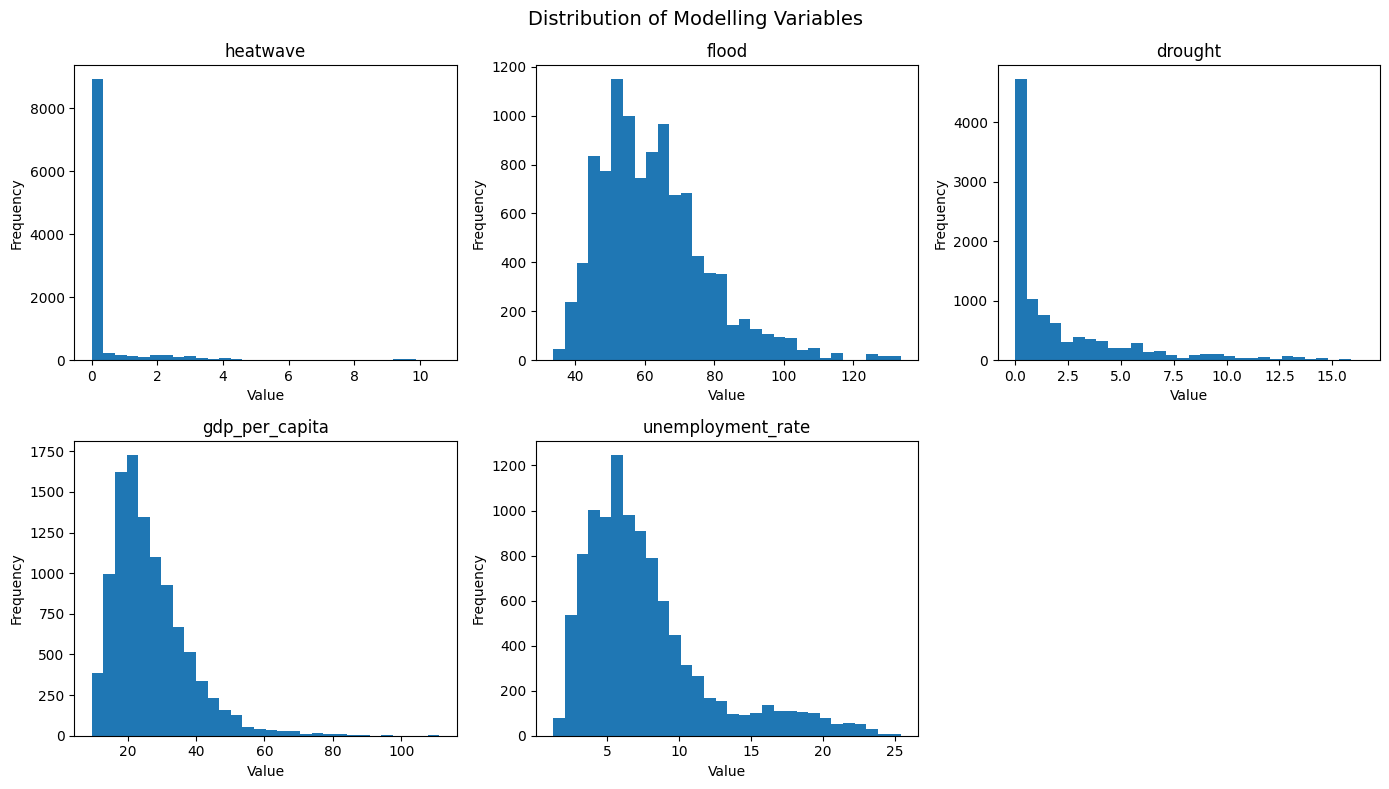

In [16]:
# ============================================================
# Histograms - Distribution of Modelling Variables
# ============================================================

numeric_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate",
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(master289[col], bins=30)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

# Hide unused 6th panel
axes[-1].axis("off")

plt.suptitle("Distribution of Modelling Variables", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** The histograms indicate that most variables are right-skewed rather than normally distributed. Heatwave and drought exhibit a high concentration of low values with a few extreme events, whereas GDP per capita and unemployment rate display broader socioeconomic variation across German districts.

#### Boxplots (Outlier Inspection)

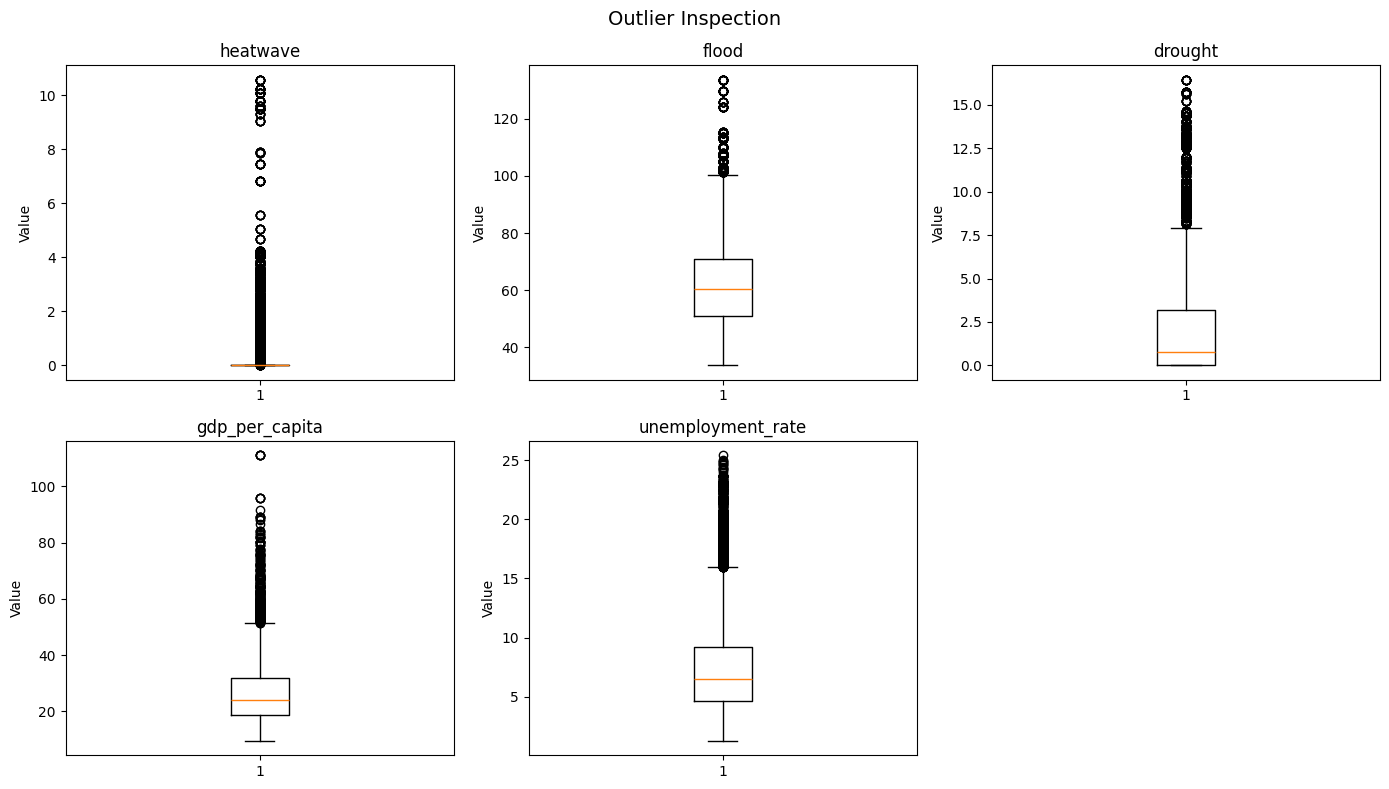

In [17]:
# ============================================================
# Boxplots - Outlier Inspection
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(master289[col].dropna(), vert=True)
    axes[i].set_title(col)
    axes[i].set_ylabel("Value")

axes[-1].axis("off")

plt.suptitle("Outlier Inspection", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** Boxplots reveal the presence of several outliers, particularly for heatwave, drought, flood, and GDP per capita. These observations represent genuine regional variability rather than data errors and were therefore retained for modelling.

#### Correlation Matrix

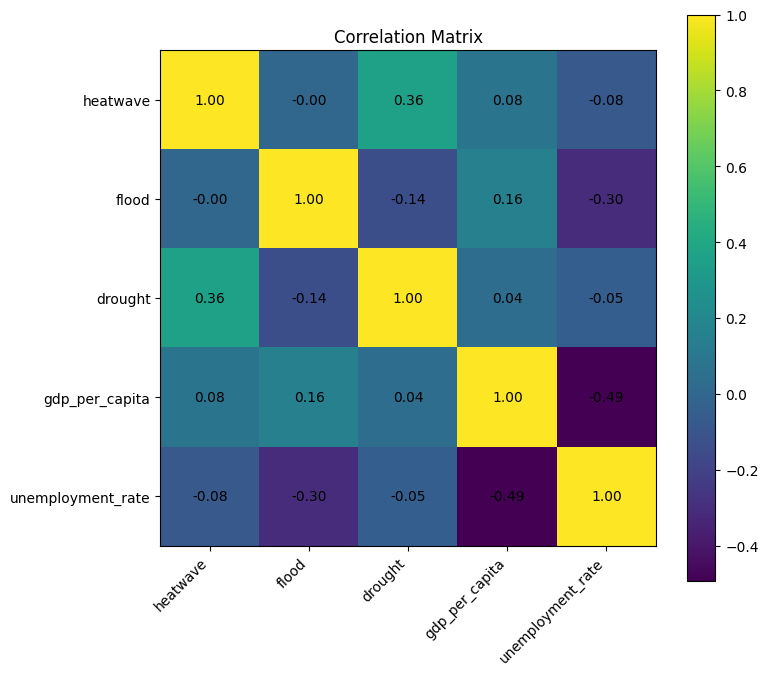

In [18]:
# ============================================================
# Correlation Matrix
# ============================================================

corr = master289[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(corr.values)

# Axis labels
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))

ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticklabels(numeric_cols)

# Write correlation values
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10,
            color="black",
        )

plt.colorbar(im)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

**Interpretation** Pairwise correlations are generally weak to moderate, indicating limited multicollinearity among predictors. The strongest association is the expected negative relationship between GDP per capita and unemployment rate (r ≈ -0.49), while heatwave and drought exhibit a moderate positive correlation (r ≈ 0.36).

#### Pairwise Relationships (Scatter Matrix)

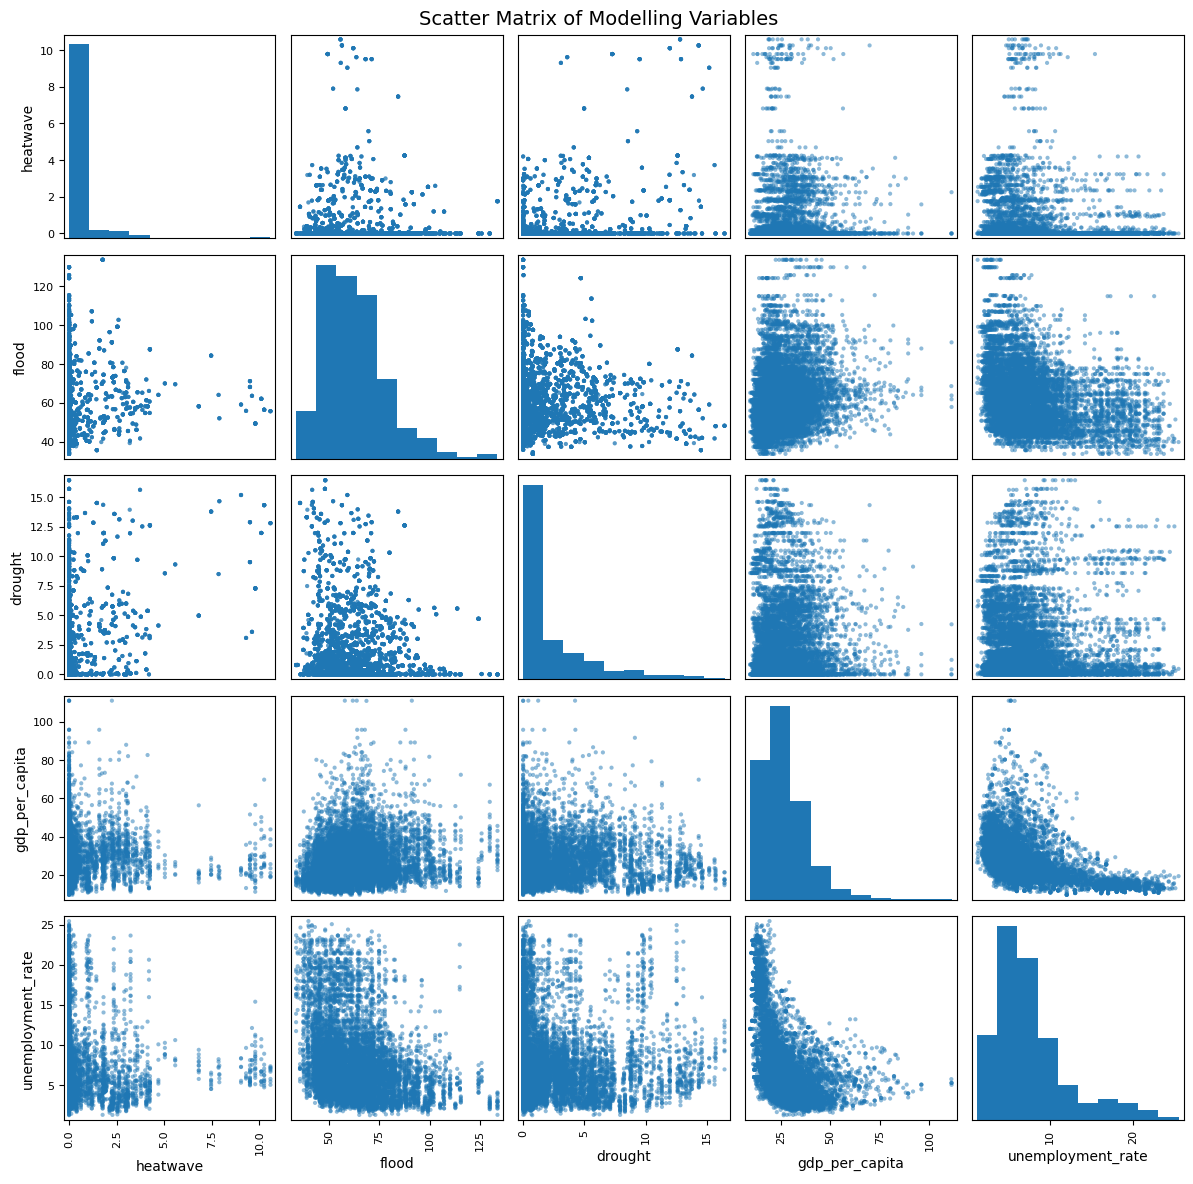

In [19]:
# ============================================================
# Pairwise Relationships (Scatter Matrix)
# ============================================================

from pandas.plotting import scatter_matrix

numeric_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate"
]

scatter_matrix(
    master289[numeric_cols],
    figsize=(12, 12),
    diagonal="hist",
    alpha=0.5,
    grid=True
)

plt.suptitle("Scatter Matrix of Modelling Variables", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** The scatter matrix confirms the correlation analysis by visualizing pairwise relationships among all modelling variables. Most feature pairs show weak nonlinear or dispersed relationships, while GDP per capita and unemployment rate demonstrate the clearest inverse association.

#### Time Trends

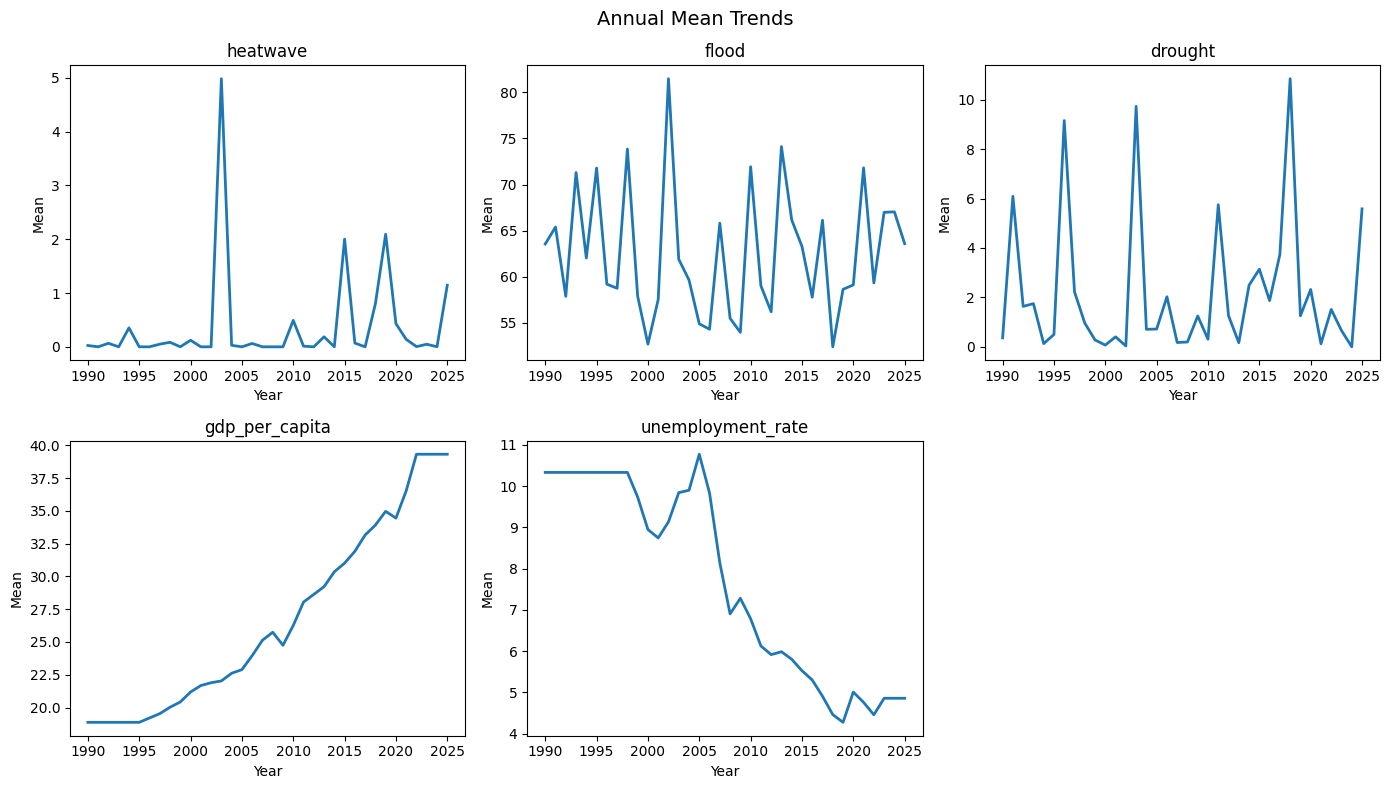

In [20]:
# ============================================================
# Mean Annual Trends
# ============================================================

yearly = master289.groupby("year")[numeric_cols].mean()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].plot(yearly.index, yearly[col], linewidth=2)
    axes[i].set_title(col)
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Mean")

axes[-1].axis("off")

plt.suptitle("Annual Mean Trends", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** Annual averages indicate a gradual increase in GDP per capita and a long-term decline in unemployment across the study period. Climate indicators exhibit substantial year-to-year variability, reflecting the episodic nature of extreme weather events rather than monotonic trends.

#### Summary Statistics

In [21]:
# ============================================================
# Exploratory Data Visualization
# ============================================================

summary = (
    master289[numeric_cols]
    .describe()
    .T
)

summary["Skewness"] = master289[numeric_cols].skew()
summary["Kurtosis"] = master289[numeric_cols].kurtosis()

summary = summary.round(2)

display(summary)

,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis
heatwave,10404.0,0.37,1.22,0.00,0.00,0.00,0.00,10.58,5.19,32.55
flood,10404.0,62.58,15.61,33.68,50.96,60.49,71.00,133.73,1.09,1.78
drought,10404.0,2.21,3.17,0.00,0.00,0.77,3.22,16.43,1.93,3.47
gdp_per_capita,10404.0,26.66,11.16,9.49,18.89,24.07,31.96,111.15,1.66,4.99
unemployment_rate,10404.0,7.67,4.43,1.25,4.63,6.52,9.16,25.43,1.46,1.93


**Interpretation:** The summary statistics indicate that the climate variables are strongly right-skewed, reflecting the infrequent occurrence of extreme weather events. In contrast, GDP per capita and unemployment rate exhibit substantial regional variation across German districts. The observed distributional characteristics motivate evaluation of feature transformations where appropriate, while the differing measurement scales justify feature scaling prior to neural network training.

**Implications for Feature Engineering**

The exploratory analysis indicates that the predictor variables exhibit different distributional characteristics. Heatwave and drought display substantial positive skewness, reflecting the infrequent occurrence of extreme climate events and a high concentration of zero or low values. Flood, GDP per capita, and unemployment rate are comparatively less skewed and retain meaningful variation on their original scales.

These distributional properties have important implications for neural network modelling. Highly skewed variables can cause a small number of extreme observations to dominate the learning process, potentially reducing model stability and predictive performance. Therefore, distributional transformations will be evaluated during the Feature Engineering stage.

Rather than applying transformations indiscriminately, each candidate transformation will be assessed quantitatively by comparing the distribution before and after transformation using summary statistics (particularly skewness) and graphical inspection. Transformations will only be retained where they demonstrably reduce skewness while preserving the interpretability of the underlying variable.

This evidence-based preprocessing strategy improves model robustness while maintaining transparency and reproducibility throughout the modelling workflow.

Consequently, the Feature Engineering stage will quantitatively evaluate a log(x + 1) transformation for the Heatwave variable and, if justified by measurable improvement in skewness, for Drought. Flood, GDP per capita, and unemployment rate will initially remain on their original scales unless further diagnostics demonstrate that transformation provides additional benefit.

### Feature Engineering & Feature Selection

Define the predictor variables used by the FFNN.

**Selected Predictor Variables (X)**

- Heatwave intensity
- Flood intensity
- Drought intensity
- GDP per capita
- Unemployment rate

**Tasks**

- Specify the predictor variables
- Verify that all predictor columns exist
- Confirm the modelling dataset is ready for partitioning
- Verify from the preceding diagnostic analysis that no problematic multicollinearity exists among the selected predictors.

**Methodological Note**

In a conventional machine learning workflow, feature selection involves identifying an optimal subset of predictors from a larger pool of candidate variables using statistical or algorithmic approaches. In this project, however, the predictor variables were specified a priori based on the IPCC Risk Framework and the availability of harmonized district-level climate and socioeconomic data. Consequently, predictor selection was performed during the project design phase based on the adopted IPCC Risk Framework and data availability, rather than within the machine learning modelling pipeline. The analyses presented in this section therefore focus on verifying the suitability, consistency, and relationships among the selected predictors prior to model development. This approach preserves the conceptual integrity of the IPCC Risk Framework while ensuring that all selected predictors satisfy the technical requirements for neural network modelling.

**Outcome:** All five predictors satisfied the feature selection and multicollinearity assessment criteria and were retained for model development.

In [22]:
# =============================================================================
# Define and Validate Predictor Variables
# =============================================================================

# Selected predictor variables (X)
predictor_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate"
]

# -------------------------------------------------------------------------
# 1. Verify that all required predictor columns exist
# -------------------------------------------------------------------------
missing_cols = [
    col for col in predictor_cols
    if col not in master289.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required predictor columns in master289: {missing_cols}"
    )

# -------------------------------------------------------------------------
# 2. Verify that predictor columns are numeric
# -------------------------------------------------------------------------
non_numeric_cols = [
    col for col in predictor_cols
    if not pd.api.types.is_numeric_dtype(master289[col])
]

if non_numeric_cols:
    raise TypeError(
        f"Non-numeric predictor columns detected: {non_numeric_cols}"
    )

# -------------------------------------------------------------------------
# 3. Verify that predictor columns contain no missing values
# -------------------------------------------------------------------------
missing_values = master289[predictor_cols].isna().sum()
missing_values = missing_values[missing_values > 0]

if not missing_values.empty:
    raise ValueError(
        "Missing values detected in predictor variables:\n"
        f"{missing_values}"
    )

# -------------------------------------------------------------------------
# 4. Confirm predictor matrix readiness
# -------------------------------------------------------------------------
X = master289[predictor_cols].copy()

print("✓ Selected predictor variables (X):")
print(predictor_cols)

print(f"\n✓ Predictor matrix shape: {X.shape}")
print(f"✓ Number of observations: {X.shape[0]:,}")
print(f"✓ Number of predictors: {X.shape[1]}")
print("✓ All predictor columns exist, are numeric, and contain no missing values.")
print("✓ Predictor matrix is ready for train/validation/test partitioning.")

✓ Selected predictor variables (X):
['heatwave', 'flood', 'drought', 'gdp_per_capita', 'unemployment_rate']

✓ Predictor matrix shape: (10404, 5)
✓ Number of observations: 10,404
✓ Number of predictors: 5
✓ All predictor columns exist, are numeric, and contain no missing values.
✓ Predictor matrix is ready for train/validation/test partitioning.


In [23]:
for col in master289.columns:
    print(col)

district_code
district_name
year
heatwave
flood
drought
gdp_per_capita
unemployment_rate


#### Multicollinearity Assessment

In [24]:
# =============================================================================
# Pairwise Correlation Assessment
# =============================================================================

corr = master289[predictor_cols].corr()

summary = []

for var1, var2 in combinations(corr.columns, 2):

    r = corr.loc[var1, var2]

    abs_r = abs(r)

    if abs_r < 0.20:
        interpretation = "Very Weak"
    elif abs_r < 0.40:
        interpretation = "Weak"
    elif abs_r < 0.60:
        interpretation = "Moderate"
    elif abs_r < 0.80:
        interpretation = "Strong"
    else:
        interpretation = "Very Strong"

    summary.append({
        "Variable Pair": f"{var1} – {var2}",
        "Correlation (r)": round(r, 2),
        "Relationship": interpretation
    })

corr_summary = (
    pd.DataFrame(summary)
      .sort_values(
          by="Correlation (r)",
          key=lambda x: x.abs(),
          ascending=False
      )
      .reset_index(drop=True)
)

print("Pairwise Correlation Summary")
display(corr_summary)

Pairwise Correlation Summary


,Variable Pair,Correlation (r),Relationship
0,gdp_per_capita – unemployment_rate,-0.49,Moderate
1,heatwave – drought,0.36,Weak
2,flood – unemployment_rate,-0.30,Weak
3,flood – gdp_per_capita,0.16,Very Weak
4,flood – drought,-0.14,Very Weak
5,heatwave – gdp_per_capita,0.08,Very Weak
6,heatwave – unemployment_rate,-0.08,Very Weak
7,drought – unemployment_rate,-0.05,Very Weak
8,drought – gdp_per_capita,0.04,Very Weak
9,heatwave – flood,-0.00,Very Weak


**Interpretation** The pairwise correlation analysis indicates generally weak relationships among the selected predictors. The strongest pairwise correlation was observed between GDP per capita and unemployment rate (r = -0.49), representing a moderate inverse socioeconomic relationship. All remaining variable pairs exhibited weak or negligible correlations (|r| < 0.40). No pairwise correlation exceeded an absolute value of 0.50, indicating that problematic multicollinearity is unlikely.

**Conclusion** Pairwise correlation analysis indicates that the selected predictor variables are not strongly linearly associated. The absence of high pairwise correlations suggests that problematic multicollinearity is unlikely. Consequently, all five predictors were retained for subsequent train/validation/test partitioning and FFNN model development.

### Random Train / Validation / Test Split

In [25]:
# =============================================================================
# 1. Train / Validation / Test Split
# =============================================================================

from sklearn.model_selection import train_test_split

# Work on a copy of the complete-case modelling dataset
data = master289.copy()

# Reproducible random seed
RANDOM_STATE = 42

# -------------------------------------------------------------------------
# First split:
# 70% training and 30% temporary data
# -------------------------------------------------------------------------

train_data, temp_data = train_test_split(
    data,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)

# -------------------------------------------------------------------------
# Second split:
# Divide the temporary 30% equally into validation and test sets
# -------------------------------------------------------------------------

validation_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True
)

# Reset indices for clean downstream processing
train_data = train_data.reset_index(drop=True)
validation_data = validation_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

# -------------------------------------------------------------------------
# Verify the partition sizes
# -------------------------------------------------------------------------

total_rows = len(data)

partition_summary = pd.DataFrame({
    "Partition": ["Training", "Validation", "Test", "Total"],
    "Rows": [
        len(train_data),
        len(validation_data),
        len(test_data),
        total_rows
    ],
    "Percentage": [
        len(train_data) / total_rows * 100,
        len(validation_data) / total_rows * 100,
        len(test_data) / total_rows * 100,
        100.0
    ]
})

print("Dataset partitioning completed successfully.\n")
display(partition_summary)

# Confirm that all rows were retained
assert (
    len(train_data) +
    len(validation_data) +
    len(test_data)
) == total_rows, "Partition sizes do not sum to the original dataset size."

Dataset partitioning completed successfully.



,Partition,Rows,Percentage
0,Training,7282,69.992311
1,Validation,1561,15.003845
2,Test,1561,15.003845
3,Total,10404,100.000000


**Interpretation.** The modelling dataset was randomly partitioned into training (70%), validation (15%), and test (15%) subsets using a fixed random seed to ensure reproducibility. The training set will be used to fit all preprocessing transformations and train the FFNN. The validation set will support hyperparameter optimization and early stopping, while the test set will remain completely unseen during model development and will be used only for the final performance evaluation.

**Conclusion.** The modelling dataset was successfully partitioned into reproducible training, validation, and test subsets, providing the foundation for leakage-free preprocessing and subsequent FFNN model development.

# Preprocessing Pipeline

1. Evaluate log(x + 1) transformations

2. Fit StandardScaler on Training Data
    - Transform Train
    - Transform Validation
    - Transform Test

### Evaluate Log(x + 1) Transformations

**Objective** Determine whether any predictor variables benefit from logarithmic transformation using only the training set.

**Tasks**
- Inspect predictor distributions in the training set
- Compare raw and log(x + 1) distributions
- Evaluate skewness reduction
- Decide which variables should be log-transformed

**Output**
- Distribution comparison plots
- Skewness comparison table
- Transformation decision for each predictor

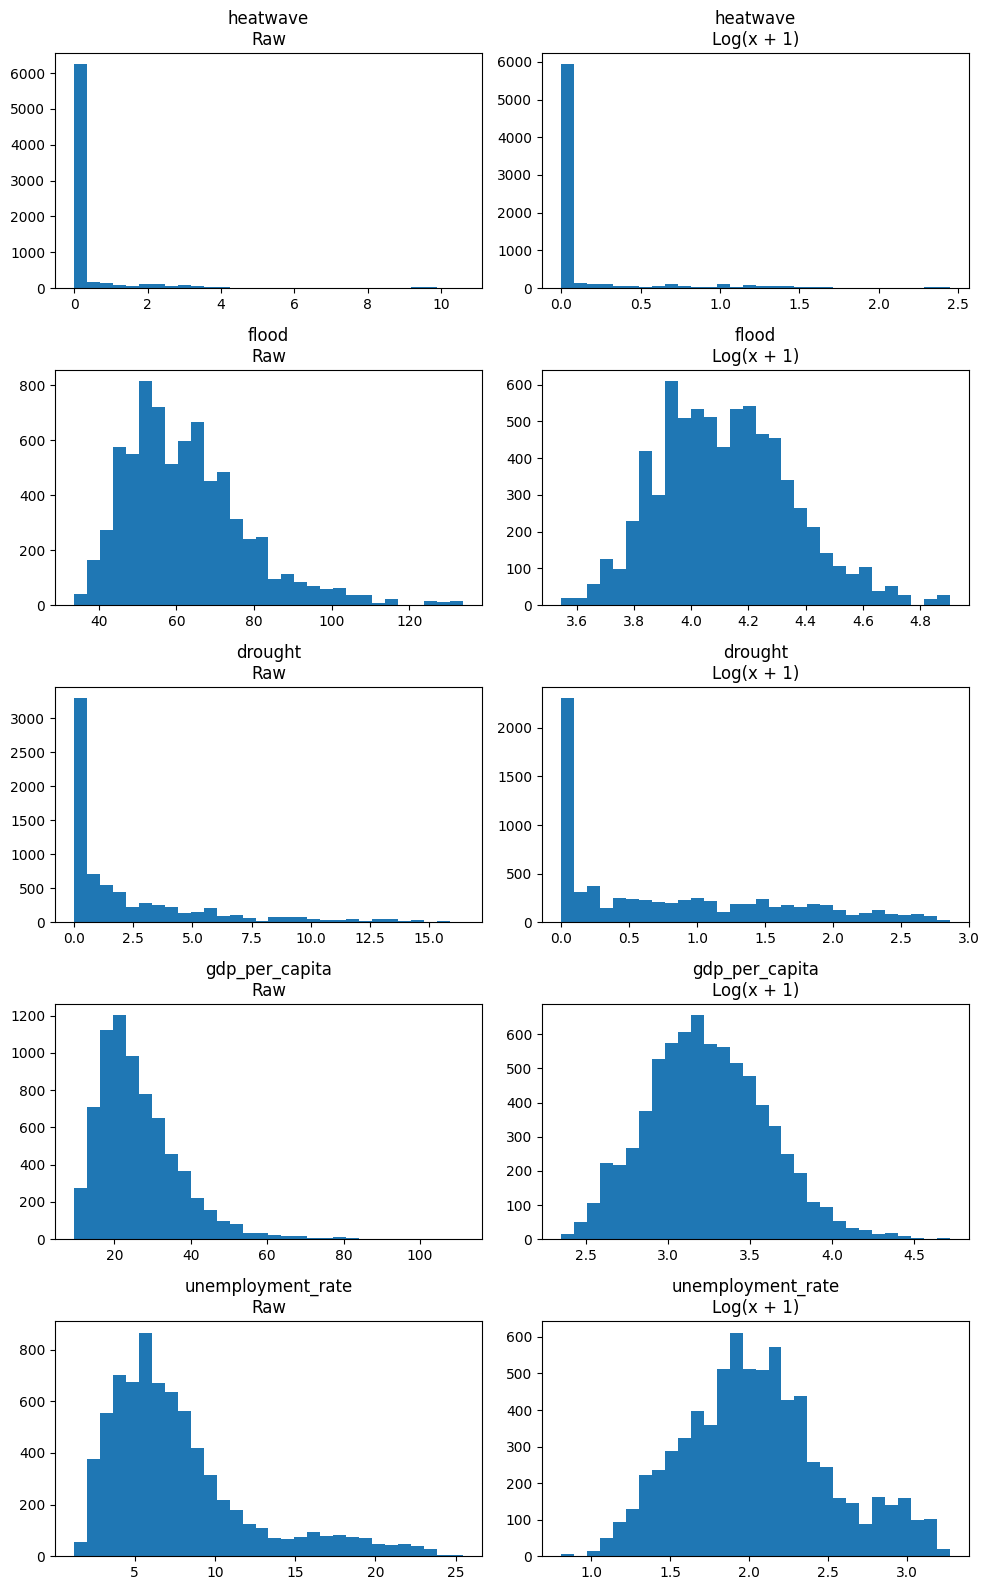

Log Transformation Assessment


,Variable,Raw Skewness,Log(x+1) Skewness,Skewness Reduction,Recommended Transformation
0,heatwave,5.27,2.99,2.29,Log(x+1)
3,gdp_per_capita,1.67,0.32,1.35,Log(x+1)
2,drought,1.93,0.69,1.23,Log(x+1)
4,unemployment_rate,1.45,0.33,1.12,Log(x+1)
1,flood,1.12,0.38,0.73,Log(x+1)


In [26]:
# =============================================================================
# Evaluate Log(x + 1) Transformations
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predictor variables
predictor_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate"
]

# -------------------------------------------------------------------------
# Evaluate candidate log(x + 1) transformations using TRAINING DATA ONLY
# -------------------------------------------------------------------------

comparison = []

fig, axes = plt.subplots(
    len(predictor_cols),
    2,
    figsize=(10, 16)
)

for i, col in enumerate(predictor_cols):

    raw = train_data[col]

    log = np.log1p(raw)

    raw_skew = raw.skew()
    log_skew = log.skew()

    comparison.append({

        "Variable": col,

        "Raw Skewness": round(raw_skew, 2),

        "Log(x+1) Skewness": round(log_skew, 2),

        "Skewness Reduction":
            round(abs(raw_skew) - abs(log_skew), 2),

        "Recommended Transformation":
            "Log(x+1)"
            if abs(log_skew) < abs(raw_skew)
            else "No"

    })

    # Raw distribution
    axes[i,0].hist(raw, bins=30)

    axes[i,0].set_title(f"{col}\nRaw")

    # Log distribution
    axes[i,1].hist(log, bins=30)

    axes[i,1].set_title(f"{col}\nLog(x + 1)")

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Summarize results
# -------------------------------------------------------------------------

transformation_summary = (
    pd.DataFrame(comparison)
    .sort_values("Skewness Reduction", ascending=False)
)

print("Log Transformation Assessment")
display(transformation_summary)

**Interpretation.** The log(x + 1) transformation reduced positive skewness for all predictor variables in the training dataset. The greatest improvement was observed for heatwave intensity, followed by GDP per capita, drought intensity, unemployment rate, and flood intensity. As each predictor exhibited a more symmetric distribution after transformation, the log(x + 1) transformation was adopted for all five variables prior to feature scaling.

**Conclusion.** All predictor variables will undergo a log(x + 1) transformation before fitting the StandardScaler. The fitted preprocessing pipeline will subsequently be applied unchanged to the validation and test datasets to prevent data leakage.

### Build the Preprocessing Pipeline

**Objective** Construct a reusable preprocessing pipeline using training data only.

**Tasks**
- Apply approved log transformations
- Fit StandardScaler on the transformed training predictors
- Store preprocessing parameters
- Create reusable preprocessing pipeline

**Output**
- Fitted preprocessing pipeline
- Fitted StandardScaler

In [27]:
# =============================================================================
# Build the Preprocessing Pipeline
# =============================================================================

# -------------------------------------------------------------------------
# Build a reusable preprocessing pipeline.
#
# The fitted pipeline stores all preprocessing decisions (log transformation
# and feature scaling) learned from the training data only. The same pipeline
# can later be saved (e.g., with joblib) and reused during validation,
# testing, and deployment to ensure identical preprocessing for every new
# observation, preventing data leakage and guaranteeing consistent model
# predictions.
# -------------------------------------------------------------------------


import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# -------------------------------------------------------------------------
# Define the approved transformation
# -------------------------------------------------------------------------
log_transformer = FunctionTransformer(
    np.log1p,
    feature_names_out="one-to-one"
)

# -------------------------------------------------------------------------
# Build the reusable preprocessing pipeline
# -------------------------------------------------------------------------

# This preprocessing pipeline becomes part of the deployed AI model.
preprocessing_pipeline = Pipeline(
    steps=[
        ("log_transform", log_transformer),
        ("standard_scaler", StandardScaler())
    ]
)

# -------------------------------------------------------------------------
# Fit the pipeline using TRAINING PREDICTORS ONLY
# -------------------------------------------------------------------------
X_train_raw = train_data[predictor_cols].copy()

preprocessing_pipeline.fit(X_train_raw)

# Access the fitted scaler stored inside the pipeline
fitted_scaler = preprocessing_pipeline.named_steps["standard_scaler"]

# -------------------------------------------------------------------------
# Verify successful fitting
# -------------------------------------------------------------------------
print("✓ Preprocessing pipeline fitted successfully.")
print("✓ Fitted using training predictors only.")
print(f"✓ Number of training observations: {len(X_train_raw):,}")
print(f"✓ Number of predictors: {len(predictor_cols)}")

print("\nPipeline steps:")
for step_name, transformer in preprocessing_pipeline.steps:
    print(f"  - {step_name}: {transformer.__class__.__name__}")

print("\nStandardScaler parameters:")
for feature, mean, scale in zip(
    predictor_cols,
    fitted_scaler.mean_,
    fitted_scaler.scale_
):
    print(
        f"  - {feature}: "
        f"mean = {mean:.4f}, "
        f"scale = {scale:.4f}"
    )

✓ Preprocessing pipeline fitted successfully.
✓ Fitted using training predictors only.
✓ Number of training observations: 7,282
✓ Number of predictors: 5

Pipeline steps:
  - log_transform: FunctionTransformer
  - standard_scaler: StandardScaler

StandardScaler parameters:
  - heatwave: mean = 0.1631, scale = 0.4271
  - flood: mean = 4.1231, scale = 0.2321
  - drought: mean = 0.8023, scale = 0.8073
  - gdp_per_capita: mean = 3.2447, scale = 0.3632
  - unemployment_rate: mean = 2.0529, scale = 0.4649


### Apply the Pipeline

**Objective** Apply the fitted preprocessing pipeline consistently to every dataset partition.

**Tasks**

- Transform training predictors
- Transform validation predictors
- Transform test predictors
- Verify transformed dataset dimensions

**Output**
 - X_train_processed
 - X_validation_processed
 - X_test_processed

In [28]:
# =============================================================================
# Apply the Fitted Preprocessing Pipeline
# =============================================================================

# -------------------------------------------------------------------------
# Extract raw predictor matrices from each dataset partition
# -------------------------------------------------------------------------
X_train_raw = train_data[predictor_cols].copy()
X_validation_raw = validation_data[predictor_cols].copy()
X_test_raw = test_data[predictor_cols].copy()

# -------------------------------------------------------------------------
# Apply the SAME fitted preprocessing pipeline to every partition
# -------------------------------------------------------------------------
X_train_processed = preprocessing_pipeline.transform(X_train_raw)
X_validation_processed = preprocessing_pipeline.transform(X_validation_raw)
X_test_processed = preprocessing_pipeline.transform(X_test_raw)

# -------------------------------------------------------------------------
# Verify transformed dataset dimensions
# -------------------------------------------------------------------------
expected_shapes = {
    "Training": (len(train_data), len(predictor_cols)),
    "Validation": (len(validation_data), len(predictor_cols)),
    "Test": (len(test_data), len(predictor_cols))
}

actual_shapes = {
    "Training": X_train_processed.shape,
    "Validation": X_validation_processed.shape,
    "Test": X_test_processed.shape
}

for partition in expected_shapes:
    assert actual_shapes[partition] == expected_shapes[partition], (
        f"{partition} processed shape mismatch: "
        f"expected {expected_shapes[partition]}, "
        f"received {actual_shapes[partition]}"
    )

print("✓ Fitted preprocessing pipeline applied successfully.")
print("✓ The pipeline was not refitted on validation or test data.")

print("\nProcessed predictor dimensions:")
for partition, shape in actual_shapes.items():
    print(f"  - {partition}: {shape}")

✓ Fitted preprocessing pipeline applied successfully.
✓ The pipeline was not refitted on validation or test data.

Processed predictor dimensions:
  - Training: (7282, 5)
  - Validation: (1561, 5)
  - Test: (1561, 5)


**Interpretation.** The fitted preprocessing pipeline was successfully applied to the training, validation, and test predictor matrices. All dataset partitions retained their expected dimensions, confirming that the preprocessing operations preserved the original observations and predictor structure. Because the pipeline was fitted exclusively on the training data and subsequently reused without refitting, identical preprocessing was applied across all partitions while preventing information leakage from the validation and test datasets.


**Conclusion.** The predictor variables are now consistently preprocessed and ready for Regional Climate Risk Score (RCRS) construction and subsequent neural network modelling. The reusable preprocessing pipeline will also be employed during model deployment to ensure that all future user inputs undergo exactly the same transformations learned during training.

# Target Variable (y) Construction - Regional Climate Risk Score (RCRS)

Construct the RCRS separately for the training, validation, and test partitions using predictor values processed by the training-fitted preprocessing pipeline.

Unlike conventional supervised learning problems, where the target variable is directly observed, this project constructs the target variable from the selected climate hazard and socioeconomic indicators. The Regional Climate Risk Score (RCRS) is therefore a constructed target variable rather than a directly observed historical outcome. Following the adopted IPCC Risk Framework, the RCRS was computed separately for the training, validation, and test partitions using the preprocessed predictor variables generated by the fitted preprocessing pipeline. The score combines climate hazard indicators with socioeconomic vulnerability and adaptive capacity indicators and serves as the response variable (y), for training the Feed-Forward Neural Network.

### Weighting Scheme

<table style="width:100%; border-collapse:collapse;">
<thead>
<tr>
<th align="left">Component</th>
<th align="left">Indicator</th>
<th align="center">Weight</th>
<th align="left">Contribution to Risk</th>
</tr>
</thead>

<tbody>

<tr>
<td>Climate Hazard</td>
<td>Heatwave intensity</td>
<td align="center">0.20</td>
<td>Higher value → Higher climate risk</td>
</tr>

<tr>
<td>Climate Hazard</td>
<td>Flood intensity</td>
<td align="center">0.20</td>
<td>Higher value → Higher climate risk</td>
</tr>

<tr>
<td>Climate Hazard</td>
<td>Drought intensity</td>
<td align="center">0.20</td>
<td>Higher value → Higher climate risk</td>
</tr>

<tr>
<td>Socioeconomic Vulnerability</td>
<td>Unemployment rate</td>
<td align="center">0.20</td>
<td>Higher value → Higher climate risk</td>
</tr>

<tr>
<td>Adaptive Capacity</td>
<td>GDP per capita</td>
<td align="center">0.20</td>
<td>Higher value → Lower climate risk</td>
</tr>

</tbody>
</table>

The raw Regional Climate Risk Score was calculated as:

Raw RCRS

RCRSraw = 0.20(H)+0.20(F)+0.20(D)+0.20(U)−0.20(G)

where

H = Heatwave intensity
F = Flood intensity
D = Drought intensity
U = Unemployment rate
G = GDP per capita

The negative coefficient for GDP per capita reflects its role as an indicator of adaptive capacity, whereby regions with greater economic capacity are assumed to exhibit lower climate risk. The raw composite score was subsequently rescaled to a bounded range of 0–100 using a MinMaxScaler fitted exclusively on the training data. The fitted scaler was then applied unchanged to the validation and test partitions to prevent data leakage.

Equal weights (0.20) were assigned to all five indicators because no empirically validated weighting scheme currently exists for this prototype. Climate hazard indicators and unemployment contribute positively to climate risk, whereas GDP per capita contributes negatively as a proxy for adaptive capacity. The raw RCRS was subsequently rescaled to a bounded range of 0–100 using a MinMaxScaler fitted exclusively on the training partition before being applied unchanged to the validation and test partitions.

The Regional Climate Risk Score (RCRS) is a constructed target variable rather than a directly observed historical outcome. It is deterministically computed from the five selected climate hazard and socioeconomic indicators following the adopted IPCC Risk Framework.

Consequently, the Feed-Forward Neural Network (FFNN) learns to approximate the IPCC-informed Regional Climate Risk Score (RCRS) from the processed predictor variables. The model should therefore be interpreted as a supervised approximation of the adopted climate risk scoring methodology rather than a predictor of independently observed historical climate risk. This prototype establishes a transparent modelling framework that can later be extended to predict empirical outcomes, such as observed climate losses, banking risk indicators, or insurance claims, when such data become available.

In [29]:
# -------------------------------------------------------------
# Regional Climate Risk Score (RCRS) Weighting Scheme
# -------------------------------------------------------------
# Equal weights (0.20) are assigned to all indicators.
# The FFNN will subsequently learn the relative importance of
# each predictor, while SHAP analysis will quantify feature
# contributions after model training.
# -------------------------------------------------------------

HEAT_WEIGHT = 0.20
FLOOD_WEIGHT = 0.20
DROUGHT_WEIGHT = 0.20
GDP_WEIGHT = 0.20
UNEMPLOYMENT_WEIGHT = 0.20

# Verify weights sum to 1
assert (
    HEAT_WEIGHT +
    FLOOD_WEIGHT +
    DROUGHT_WEIGHT +
    GDP_WEIGHT +
    UNEMPLOYMENT_WEIGHT
) == 1.0

In [30]:
# =============================================================================
# Construct the Regional Climate Risk Score (RCRS)
# =============================================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# -----------------------------------------------------------------------------
# Reconstruct processed predictor matrices as labelled DataFrames
# -----------------------------------------------------------------------------
X_train_df = pd.DataFrame(
    X_train_processed,
    columns=predictor_cols,
    index=train_data.index
)

X_validation_df = pd.DataFrame(
    X_validation_processed,
    columns=predictor_cols,
    index=validation_data.index
)

X_test_df = pd.DataFrame(
    X_test_processed,
    columns=predictor_cols,
    index=test_data.index
)


rcrs_weights = {
    "heatwave": 0.20,
    "flood": 0.20,
    "drought": 0.20,
    "gdp_per_capita": -0.20,
    "unemployment_rate": 0.20
}

# Confirm that the absolute weights sum to 1.0
assert np.isclose(
    sum(abs(weight) for weight in rcrs_weights.values()),
    1.0
), "The absolute RCRS weights must sum to 1.0."

# -----------------------------------------------------------------------------
# Function to calculate the unbounded composite score
# -----------------------------------------------------------------------------
def calculate_raw_rcrs(processed_data, weights):
    """Calculate the direction-adjusted weighted RCRS composite."""

    return sum(
        processed_data[variable] * weight
        for variable, weight in weights.items()
    )

# Construct raw RCRS values separately for each partition
rcrs_train_raw = calculate_raw_rcrs(X_train_df, rcrs_weights)
rcrs_validation_raw = calculate_raw_rcrs(
    X_validation_df,
    rcrs_weights
)
rcrs_test_raw = calculate_raw_rcrs(X_test_df, rcrs_weights)

# -----------------------------------------------------------------------------
# Convert the raw composite to a bounded 0–100 score
#
# Fit the score scaler using TRAINING SCORES ONLY.
# Validation and test scores use the same fitted mapping.
# -----------------------------------------------------------------------------
rcrs_scaler = MinMaxScaler(
    feature_range=(0, 100),
    clip=True
)

y_train = rcrs_scaler.fit_transform(
    rcrs_train_raw.to_numpy().reshape(-1, 1)
).ravel()

y_validation = rcrs_scaler.transform(
    rcrs_validation_raw.to_numpy().reshape(-1, 1)
).ravel()

y_test = rcrs_scaler.transform(
    rcrs_test_raw.to_numpy().reshape(-1, 1)
).ravel()

# Append the target to each partition for traceability
train_data = train_data.copy()
validation_data = validation_data.copy()
test_data = test_data.copy()

train_data["rcrs"] = y_train
validation_data["rcrs"] = y_validation
test_data["rcrs"] = y_test

# -----------------------------------------------------------------------------
# Validation checks
# -----------------------------------------------------------------------------
for partition_name, target in {
    "Training": y_train,
    "Validation": y_validation,
    "Test": y_test
}.items():

    assert len(target) > 0, (
        f"{partition_name} RCRS target is empty."
    )

    assert np.isfinite(target).all(), (
        f"{partition_name} RCRS contains non-finite values."
    )

    assert ((target >= 0) & (target <= 100)).all(), (
        f"{partition_name} RCRS values fall outside the 0–100 range."
    )

rcrs_summary = pd.DataFrame({
    "Partition": ["Training", "Validation", "Test"],
    "Rows": [
        len(y_train),
        len(y_validation),
        len(y_test)
    ],
    "Minimum": [
        y_train.min(),
        y_validation.min(),
        y_test.min()
    ],
    "Mean": [
        y_train.mean(),
        y_validation.mean(),
        y_test.mean()
    ],
    "Median": [
        np.median(y_train),
        np.median(y_validation),
        np.median(y_test)
    ],
    "Maximum": [
        y_train.max(),
        y_validation.max(),
        y_test.max()
    ],
    "Standard Deviation": [
        y_train.std(),
        y_validation.std(),
        y_test.std()
    ]
}).round(2)

print("✓ RCRS constructed successfully for all dataset partitions.")
print("✓ Indicator directions and weights applied consistently.")
print("✓ RCRS scaler fitted using training scores only.")
print("✓ All RCRS values are bounded between 0 and 100.")

display(rcrs_summary)

✓ RCRS constructed successfully for all dataset partitions.
✓ Indicator directions and weights applied consistently.
✓ RCRS scaler fitted using training scores only.
✓ All RCRS values are bounded between 0 and 100.


,Partition,Rows,Minimum,Mean,Median,Maximum,Standard Deviation
0,Training,7282,0.00,38.52,36.93,100.00,14.41
1,Validation,1561,3.55,38.35,37.11,98.32,14.60
2,Test,1561,1.05,38.14,36.85,92.64,14.47


**Interpretation.** The Regional Climate Risk Score (RCRS) exhibited highly consistent distributions across the training, validation, and test partitions. Mean, median, and standard deviation values were nearly identical, indicating that random partitioning preserved the overall characteristics of the modelling dataset. As expected, only the training partition spans the full 0–100 range because the MinMaxScaler was fitted exclusively on the training data and subsequently applied unchanged to the validation and test partitions.

**Conclusion.** The constructed target variable (RCRS) is well balanced across all dataset partitions and is suitable for supervised FFNN training, validation, and independent model evaluation.

### Convert to PyTorch Tensors

**Objective** Convert the processed predictor matrices and RCRS target arrays into PyTorch-compatible tensors for neural network training, validation, and testing.

**Tasks**

- Convert predictors to float32 tensors
- Convert RCRS targets to float32 column tensors
- Create TensorDataset objects
- Create DataLoader objects
- Shuffle the training data only
- Verify tensor and batch dimensions

**Output**

- X_train_tensor, X_validation_tensor, X_test_tensor
- y_train_tensor, y_validation_tensor, y_test_tensor
- train_loader, validation_loader, test_loader

In [31]:
# =============================================================================
# Convert Processed Data to PyTorch Tensors
# =============================================================================

import torch
from torch.utils.data import TensorDataset, DataLoader

# -----------------------------------------------------------------------------
# Reproducibility and DataLoader configuration
# -----------------------------------------------------------------------------
TORCH_SEED = 42
BATCH_SIZE = 64

torch.manual_seed(TORCH_SEED)

# -----------------------------------------------------------------------------
# Convert processed predictor matrices to float32 tensors
# -----------------------------------------------------------------------------
X_train_tensor = torch.tensor(
    X_train_processed,
    dtype=torch.float32
)

X_validation_tensor = torch.tensor(
    X_validation_processed,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_processed,
    dtype=torch.float32
)

# -----------------------------------------------------------------------------
# Convert RCRS target arrays to float32 column tensors
#
# reshape(-1, 1) ensures that each target has shape [n_observations, 1],
# matching the single-output FFNN architecture.
# -----------------------------------------------------------------------------
y_train_tensor = torch.tensor(
    y_train.reshape(-1, 1),
    dtype=torch.float32
)

y_validation_tensor = torch.tensor(
    y_validation.reshape(-1, 1),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.reshape(-1, 1),
    dtype=torch.float32
)

# -----------------------------------------------------------------------------
# Create TensorDataset objects
# -----------------------------------------------------------------------------
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

validation_dataset = TensorDataset(
    X_validation_tensor,
    y_validation_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

# -----------------------------------------------------------------------------
# Create DataLoader objects
#
# Training data are shuffled at the beginning of each epoch.
# Validation and test data remain ordered because no parameter updates occur.
# -----------------------------------------------------------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# -----------------------------------------------------------------------------
# Validation checks
# -----------------------------------------------------------------------------
assert X_train_tensor.shape == (
    len(train_data),
    len(predictor_cols)
)

assert X_validation_tensor.shape == (
    len(validation_data),
    len(predictor_cols)
)

assert X_test_tensor.shape == (
    len(test_data),
    len(predictor_cols)
)

assert y_train_tensor.shape == (
    len(train_data),
    1
)

assert y_validation_tensor.shape == (
    len(validation_data),
    1
)

assert y_test_tensor.shape == (
    len(test_data),
    1
)

# Inspect one training batch
X_batch, y_batch = next(iter(train_loader))

print("✓ Processed predictors and RCRS targets converted to PyTorch tensors.")
print("✓ TensorDataset and DataLoader objects created successfully.")
print("✓ Training DataLoader configured with shuffling.")
print("✓ Validation and test DataLoaders configured without shuffling.")

print("\nTensor dimensions:")
print(f"  - X_train_tensor:      {tuple(X_train_tensor.shape)}")
print(f"  - y_train_tensor:      {tuple(y_train_tensor.shape)}")
print(f"  - X_validation_tensor: {tuple(X_validation_tensor.shape)}")
print(f"  - y_validation_tensor: {tuple(y_validation_tensor.shape)}")
print(f"  - X_test_tensor:       {tuple(X_test_tensor.shape)}")
print(f"  - y_test_tensor:       {tuple(y_test_tensor.shape)}")

print("\nExample training batch:")
print(f"  - Predictor batch shape: {tuple(X_batch.shape)}")
print(f"  - Target batch shape:    {tuple(y_batch.shape)}")

print("\nDataLoader batches:")
print(f"  - Training batches:   {len(train_loader)}")
print(f"  - Validation batches: {len(validation_loader)}")
print(f"  - Test batches:       {len(test_loader)}")

✓ Processed predictors and RCRS targets converted to PyTorch tensors.
✓ TensorDataset and DataLoader objects created successfully.
✓ Training DataLoader configured with shuffling.
✓ Validation and test DataLoaders configured without shuffling.

Tensor dimensions:
  - X_train_tensor:      (7282, 5)
  - y_train_tensor:      (7282, 1)
  - X_validation_tensor: (1561, 5)
  - y_validation_tensor: (1561, 1)
  - X_test_tensor:       (1561, 5)
  - y_test_tensor:       (1561, 1)

Example training batch:
  - Predictor batch shape: (64, 5)
  - Target batch shape:    (64, 1)

DataLoader batches:
  - Training batches:   114
  - Validation batches: 25
  - Test batches:       25


### Build Feed-Forward Neural Network (FFNN) (PyTorch)

**Objective** Define a reusable regression network that maps the five processed predictor variables to one continuous Regional Climate Risk Score.

**Architecture**

- Input layer: 5 predictors
- Hidden layer 1: 64 neurons
- ReLU activation
- Dropout regularization
- Hidden layer 2: 32 neurons
- ReLU activation
- Dropout regularization
- Output layer: 1 continuous RCRS value

**Tasks**

- Define the FFNN model class
- Parameterize hidden-layer sizes and dropout
- Instantiate a baseline model
- Verify input and output dimensions
- Count trainable parameters

**Output**

- Reusable FFNNRegressor class
- Baseline model instance
- Successful forward-pass verification

In [32]:
# =============================================================================
# Build the Feed-Forward Neural Network (FFNN)
# =============================================================================

import torch
import torch.nn as nn

# -----------------------------------------------------------------------------
# Define a reusable FFNN regression architecture
# -----------------------------------------------------------------------------
class FFNNRegressor(nn.Module):
    """Feed-forward neural network for continuous RCRS prediction."""

    def __init__(
        self,
        input_dim,
        hidden_dim_1=64,
        hidden_dim_2=32,
        dropout_rate=0.20
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim_1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(hidden_dim_1, hidden_dim_2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(hidden_dim_2, 1)
        )

    def forward(self, x):
        return self.network(x)


# -----------------------------------------------------------------------------
# Instantiate the baseline FFNN
# -----------------------------------------------------------------------------
INPUT_DIM = len(predictor_cols)

baseline_model = FFNNRegressor(
    input_dim=INPUT_DIM,
    hidden_dim_1=64,
    hidden_dim_2=32,
    dropout_rate=0.20
)

# -----------------------------------------------------------------------------
# Verify architecture with one training batch
# -----------------------------------------------------------------------------
baseline_model.eval()

with torch.no_grad():
    sample_predictions = baseline_model(X_batch)

assert sample_predictions.shape == y_batch.shape, (
    "Model output shape does not match the target batch shape."
)

# Count trainable parameters
trainable_parameters = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
    if parameter.requires_grad
)

print("✓ FFNN architecture created successfully.")
print("✓ Forward pass completed successfully.")
print("✓ Model output shape matches the RCRS target shape.")

print("\nBaseline architecture:")
print(baseline_model)

print("\nDimension check:")
print(f"  - Input batch shape:  {tuple(X_batch.shape)}")
print(f"  - Output batch shape: {tuple(sample_predictions.shape)}")
print(f"  - Target batch shape: {tuple(y_batch.shape)}")

print(f"\nTrainable parameters: {trainable_parameters:,}")

✓ FFNN architecture created successfully.
✓ Forward pass completed successfully.
✓ Model output shape matches the RCRS target shape.

Baseline architecture:
FFNNRegressor(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Dimension check:
  - Input batch shape:  (64, 5)
  - Output batch shape: (64, 1)
  - Target batch shape: (64, 1)

Trainable parameters: 2,497


### Configure Training and Hyperparameter Tuning

**Objective** Define the baseline training settings and hyperparameter search space used to identify the best-performing FFNN configuration based on validation loss.

**Tasks**

- Define the regression loss function
- Select the optimizer
- Set the batch size

- Define the hyperparameter search space
    - Learning rates
    - Hidden-layer sizes
    - Dropout rates
    
    
- Set the maximum number of epochs
- Configure early stopping
    - Patience
    - MIN_DELTA
    - Restore_best_model_state
- Store all candidate configurations reproducibly

**Output**

- Regression loss function (MSELoss)
- Hyperparameter search space
- Early stopping settings
- Reproducible final Training Configuration
(selected through hyperparameter tuning)

In [33]:
# =============================================================================
# Configure Training and Hyperparameter Tuning
# =============================================================================

import itertools
import torch
import torch.nn as nn
import torch.optim as optim

# -----------------------------------------------------------------------------
# Reproducibility
# -----------------------------------------------------------------------------
TUNING_SEED = 42
torch.manual_seed(TUNING_SEED)

# -----------------------------------------------------------------------------
# Regression loss function
#
# MSELoss measures the average squared difference between predicted and
# observed RCRS values. Larger prediction errors are penalized more strongly.
# -----------------------------------------------------------------------------
criterion = nn.MSELoss()

# -----------------------------------------------------------------------------
# Baseline training configuration
# -----------------------------------------------------------------------------

# Early stopping:
#   patience = 20 epochs
#   min_delta = 0.0001 (minimum validation loss improvement required
#   to reset the early stopping counter)

BATCH_SIZE = 64
MAX_EPOCHS = 200
EARLY_STOPPING_PATIENCE = 20
MIN_DELTA = 0.0001
# -----------------------------------------------------------------------------
# Hyperparameter search space
#
# Each candidate configuration will later be trained on the training set and
# compared using validation loss. The test set remains completely untouched.
# -----------------------------------------------------------------------------
hyperparameter_grid = {
    "hidden_dim_1": [32, 64],
    "hidden_dim_2": [16, 32],
    "dropout_rate": [0.10, 0.20],
    "learning_rate": [0.001, 0.0005]
}

# Generate every candidate combination
hyperparameter_combinations = list(
    itertools.product(
        hyperparameter_grid["hidden_dim_1"],
        hyperparameter_grid["hidden_dim_2"],
        hyperparameter_grid["dropout_rate"],
        hyperparameter_grid["learning_rate"]
    )
)

candidate_configs = [
    {
        "hidden_dim_1": hidden_dim_1,
        "hidden_dim_2": hidden_dim_2,
        "dropout_rate": dropout_rate,
        "learning_rate": learning_rate
    }
    for (
        hidden_dim_1,
        hidden_dim_2,
        dropout_rate,
        learning_rate
    ) in hyperparameter_combinations
]

# -----------------------------------------------------------------------------
# Baseline optimizer example
#
# A fresh optimizer must be created for every candidate model during tuning.
# This baseline optimizer is included only to document the intended optimizer.
# -----------------------------------------------------------------------------
baseline_optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

# -----------------------------------------------------------------------------
# Validation checks
# -----------------------------------------------------------------------------
assert MAX_EPOCHS > 0
assert EARLY_STOPPING_PATIENCE > 0
assert MIN_DELTA >= 0
assert len(candidate_configs) > 0

for config in candidate_configs:
    assert config["hidden_dim_1"] > 0
    assert config["hidden_dim_2"] > 0
    assert 0.0 <= config["dropout_rate"] < 1.0
    assert config["learning_rate"] > 0

print("✓ Training configuration created successfully.")
print("✓ MSELoss selected for continuous RCRS prediction.")
print("✓ Adam selected as the optimizer.")
print("✓ Early stopping parameters configured.")
print("✓ Hyperparameter search space generated successfully.")

print("\nTraining settings:")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Maximum epochs: {MAX_EPOCHS}")
print(f"  - Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"  - Minimum validation improvement (min_delta): {MIN_DELTA:.4f}")

print("\nHyperparameter search space:")
for parameter, values in hyperparameter_grid.items():
    print(f"  - {parameter}: {values}")

print(f"\nTotal hyperparameter configurations: {len(candidate_configs)}")

print("\nExample FFNN configuration:")
print(candidate_configs[0])

✓ Training configuration created successfully.
✓ MSELoss selected for continuous RCRS prediction.
✓ Adam selected as the optimizer.
✓ Early stopping parameters configured.
✓ Hyperparameter search space generated successfully.

Training settings:
  - Batch size: 64
  - Maximum epochs: 200
  - Early stopping patience: 20
  - Minimum validation improvement (min_delta): 0.0001

Hyperparameter search space:
  - hidden_dim_1: [32, 64]
  - hidden_dim_2: [16, 32]
  - dropout_rate: [0.1, 0.2]
  - learning_rate: [0.001, 0.0005]

Total hyperparameter configurations: 16

Example FFNN configuration:
{'hidden_dim_1': 32, 'hidden_dim_2': 16, 'dropout_rate': 0.1, 'learning_rate': 0.001}


### Train the FFNN

**Objective** Train and compare all FFNN configurations using the training partition and select the best-performing configuration based on validation loss.

**Tasks**

- Build a fresh FFNN for each hyperparameter configuration
- Create a separate Adam optimizer for each model
- Train each configuration using mini-batches
- Calculate training and validation loss after every epoch
- Apply early stopping using validation loss
- Preserve the best weights for each configuration
- Compare all configurations consistently
- Select the model with the lowest validation loss

**Output**

- Training history for every FFNN configuration
- Hyperparameter tuning results table
- Best-performing FFNN configuration
- Best model weights restored
- Final model ready for independent test-set evaluation

In [34]:
# =============================================================================
# Train and Compare All FFNN Configurations
# =============================================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.optim as optim

# -----------------------------------------------------------------------------
# Select computation device
# -----------------------------------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Training device: {device}")

# -----------------------------------------------------------------------------
# Evaluate one model on a DataLoader
# -----------------------------------------------------------------------------
def evaluate_loss(model, data_loader, loss_function, device):
    """
    Calculate the average loss across all observations in a DataLoader.
    """

    model.eval()

    total_loss = 0.0
    total_observations = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = loss_function(predictions, y_batch)

            batch_size = X_batch.size(0)

            total_loss += loss.item() * batch_size
            total_observations += batch_size

    return total_loss / total_observations


# -----------------------------------------------------------------------------
# Train one FFNN configuration
# -----------------------------------------------------------------------------
def train_configuration(
    configuration,
    configuration_number,
    train_loader,
    validation_loader,
    loss_function,
    max_epochs,
    patience,
    min_delta,
    device,
    seed
):
    """
    Train one FFNN configuration with early stopping.

    The best model weights are preserved whenever validation loss improves
    by at least min_delta. Training stops after 'patience' consecutive
    epochs without sufficient validation improvement.
    """

    # Reproducible initialization for this configuration
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Build a fresh model
    model = FFNNRegressor(
        input_dim=INPUT_DIM,
        hidden_dim_1=configuration["hidden_dim_1"],
        hidden_dim_2=configuration["hidden_dim_2"],
        dropout_rate=configuration["dropout_rate"]
    ).to(device)

    # Create a fresh optimizer for this model
    optimizer = optim.Adam(
        model.parameters(),
        lr=configuration["learning_rate"]
    )

    training_losses = []
    validation_losses = []

    best_validation_loss = np.inf
    best_model_state = None
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, max_epochs + 1):

        # ---------------------------------------------------------------------
        # Training phase
        # ---------------------------------------------------------------------
        model.train()

        running_training_loss = 0.0
        training_observations = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Clear gradients from the previous batch
            optimizer.zero_grad()

            # Forward pass
            predictions = model(X_batch)

            # Calculate current batch loss
            loss = loss_function(predictions, y_batch)

            # Backpropagation
            loss.backward()

            # Update weights and biases
            optimizer.step()

            batch_size = X_batch.size(0)

            running_training_loss += loss.item() * batch_size
            training_observations += batch_size

        average_training_loss = (
            running_training_loss / training_observations
        )

        # ---------------------------------------------------------------------
        # Validation phase
        # ---------------------------------------------------------------------
        average_validation_loss = evaluate_loss(
            model=model,
            data_loader=validation_loader,
            loss_function=loss_function,
            device=device
        )

        training_losses.append(average_training_loss)
        validation_losses.append(average_validation_loss)

        # ---------------------------------------------------------------------
        # Early stopping check
        # ---------------------------------------------------------------------
        meaningful_improvement = (
            average_validation_loss
            < best_validation_loss - min_delta
        )

        if meaningful_improvement:
            best_validation_loss = average_validation_loss
            best_epoch = epoch

            # Preserve an independent copy of the best weights
            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    # Restore the best-performing weights, not the final-epoch weights
    model.load_state_dict(best_model_state)

    history = {
        "training_loss": training_losses,
        "validation_loss": validation_losses
    }

    result = {
        "configuration_number": configuration_number,
        "hidden_dim_1": configuration["hidden_dim_1"],
        "hidden_dim_2": configuration["hidden_dim_2"],
        "dropout_rate": configuration["dropout_rate"],
        "learning_rate": configuration["learning_rate"],
        "epochs_completed": len(training_losses),
        "best_epoch": best_epoch,
        "best_validation_mse": best_validation_loss,
        "best_validation_rmse": np.sqrt(best_validation_loss)
    }

    return model, history, result


# -----------------------------------------------------------------------------
# Train all hyperparameter configurations
# -----------------------------------------------------------------------------
all_models = []
all_histories = []
tuning_results = []

total_configurations = len(candidate_configs)

print(
    f"\nBeginning hyperparameter tuning across "
    f"{total_configurations} FFNN configurations...\n"
)

for configuration_number, configuration in enumerate(
    candidate_configs,
    start=1
):

    print(
        f"Training configuration "
        f"{configuration_number}/{total_configurations}: "
        f"{configuration}"
    )

    trained_model, training_history, result = train_configuration(
        configuration=configuration,
        configuration_number=configuration_number,
        train_loader=train_loader,
        validation_loader=validation_loader,
        loss_function=criterion,
        max_epochs=MAX_EPOCHS,
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=MIN_DELTA,
        device=device,
        seed=TUNING_SEED + configuration_number
    )

    all_models.append(trained_model)
    all_histories.append(training_history)
    tuning_results.append(result)

    print(
        f"  Best epoch: {result['best_epoch']} | "
        f"Validation MSE: "
        f"{result['best_validation_mse']:.4f} | "
        f"Validation RMSE: "
        f"{result['best_validation_rmse']:.4f}\n"
    )


# -----------------------------------------------------------------------------
# Create and rank the tuning-results table
# -----------------------------------------------------------------------------
tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values(
        by="best_validation_mse",
        ascending=True
    )
    .reset_index(drop=True)
)

# Rank 1 represents the best-performing configuration
tuning_results_df.insert(
    0,
    "rank",
    range(1, len(tuning_results_df) + 1)
)

# -----------------------------------------------------------------------------
# Identify the overall best model
# -----------------------------------------------------------------------------
best_result = tuning_results_df.iloc[0]

best_configuration_number = int(
    best_result["configuration_number"]
)

best_model = all_models[
    best_configuration_number - 1
]

best_training_history = all_histories[
    best_configuration_number - 1
]

best_configuration = {
    "hidden_dim_1": int(best_result["hidden_dim_1"]),
    "hidden_dim_2": int(best_result["hidden_dim_2"]),
    "dropout_rate": float(best_result["dropout_rate"]),
    "learning_rate": float(best_result["learning_rate"])
}

# Keep the selected model ready for evaluation
best_model.eval()

# -----------------------------------------------------------------------------
# Final validation checks
# -----------------------------------------------------------------------------
assert len(tuning_results_df) == total_configurations
assert np.isfinite(
    tuning_results_df["best_validation_mse"]
).all()

assert best_result["rank"] == 1
assert best_result["best_validation_mse"] == (
    tuning_results_df["best_validation_mse"].min()
)

print("✓ All FFNN configurations trained successfully.")
print("✓ Early stopping applied independently to every configuration.")
print("✓ Best weights restored for every trained model.")
print("✓ Overall best model selected using validation loss only.")

print("\nFinal training configuration")
print("(best hyperparameter combination):")

for parameter, value in best_configuration.items():
    print(f"  - {parameter}: {value}")

print(f"  - Best epoch: {int(best_result['best_epoch'])}")
print(
    f"  - Epochs completed: "
    f"{int(best_result['epochs_completed'])}"
)
print(
    f"  - Best validation MSE: "
    f"{best_result['best_validation_mse']:.4f}"
)
print(
    f"  - Best validation RMSE: "
    f"{best_result['best_validation_rmse']:.4f}"
)

print("\nRanked hyperparameter tuning results:")
display(
    tuning_results_df.round(4)
)

Training device: cpu

Beginning hyperparameter tuning across 16 FFNN configurations...

Training configuration 1/16: {'hidden_dim_1': 32, 'hidden_dim_2': 16, 'dropout_rate': 0.1, 'learning_rate': 0.001}
  Best epoch: 70 | Validation MSE: 0.1818 | Validation RMSE: 0.4264

Training configuration 2/16: {'hidden_dim_1': 32, 'hidden_dim_2': 16, 'dropout_rate': 0.1, 'learning_rate': 0.0005}
  Best epoch: 78 | Validation MSE: 0.1880 | Validation RMSE: 0.4336

Training configuration 3/16: {'hidden_dim_1': 32, 'hidden_dim_2': 16, 'dropout_rate': 0.2, 'learning_rate': 0.001}
  Best epoch: 88 | Validation MSE: 0.2830 | Validation RMSE: 0.5319

Training configuration 4/16: {'hidden_dim_1': 32, 'hidden_dim_2': 16, 'dropout_rate': 0.2, 'learning_rate': 0.0005}
  Best epoch: 61 | Validation MSE: 1.9993 | Validation RMSE: 1.4140

Training configuration 5/16: {'hidden_dim_1': 32, 'hidden_dim_2': 32, 'dropout_rate': 0.1, 'learning_rate': 0.001}
  Best epoch: 46 | Validation MSE: 0.1609 | Validation RMSE

,rank,configuration_number,hidden_dim_1,hidden_dim_2,dropout_rate,learning_rate,epochs_completed,best_epoch,best_validation_mse,best_validation_rmse
0,1,14,64,32,0.1,0.0005,129,109,0.0814,0.2852
1,2,15,64,32,0.2,0.0010,112,92,0.0948,0.3078
2,3,13,64,32,0.1,0.0010,70,50,0.1029,0.3207
3,4,10,64,16,0.1,0.0005,112,92,0.1194,0.3455
4,5,6,32,32,0.1,0.0005,111,91,0.1602,0.4003
5,6,5,32,32,0.1,0.0010,66,46,0.1609,0.4011
6,7,1,32,16,0.1,0.0010,90,70,0.1818,0.4264
7,8,2,32,16,0.1,0.0005,98,78,0.1880,0.4336
8,9,16,64,32,0.2,0.0005,126,106,0.2335,0.4832
9,10,9,64,16,0.1,0.0010,72,52,0.2360,0.4858


#### Retrain the final model using the selected hyperparameters

In [45]:
# ============================================================
# Retrain the final FFNN using the selected hyperparameters
# ============================================================

# Best hyperparameters selected during grid search
# ------------------------------------------------
# Hidden layer 1 : 64 neurons
# Hidden layer 2 : 32 neurons
# Dropout rate   : 0.10
# Learning rate  : 0.0005
# Best epoch     : 109


# ------------------------------------------------------------
# Retrieve the highest-ranked configuration
# ------------------------------------------------------------
# The tuning results were ranked by validation MSE, so the
# first row contains the best-performing configuration.

best_row = tuning_results_df.iloc[0]

best_config = {
    "hidden_dim_1": int(best_row["hidden_dim_1"]),
    "hidden_dim_2": int(best_row["hidden_dim_2"]),
    "dropout_rate": float(best_row["dropout_rate"]),
    "learning_rate": float(best_row["learning_rate"]),
}

best_epoch = int(best_row["best_epoch"])


print("Selected final FFNN configuration:")
print(f"  - Hidden layer 1: {best_config['hidden_dim_1']} neurons")
print(f"  - Hidden layer 2: {best_config['hidden_dim_2']} neurons")
print(f"  - Dropout rate: {best_config['dropout_rate']}")
print(f"  - Learning rate: {best_config['learning_rate']}")
print(f"  - Selected training epochs: {best_epoch}")


# ------------------------------------------------------------
# Combine the training and validation tensors
# ------------------------------------------------------------
# The validation dataset has already served its purpose during
# hyperparameter selection. It is now combined with the training
# dataset so that the final model learns from more observations.
#
# The test dataset remains completely untouched.

X_final_train_tensor = torch.cat(
    [X_train_tensor, X_validation_tensor],
    dim=0
)

y_final_train_tensor = torch.cat(
    [y_train_tensor, y_validation_tensor],
    dim=0
)


# Create the final training dataset and DataLoader
final_train_dataset = torch.utils.data.TensorDataset(
    X_final_train_tensor,
    y_final_train_tensor
)

# Reproducible shuffling
final_loader_generator = torch.Generator()
final_loader_generator.manual_seed(TUNING_SEED)

final_train_loader = torch.utils.data.DataLoader(
    final_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=final_loader_generator
)


print("\nFinal training dataset:")
print(f"  - Predictor tensor shape: {tuple(X_final_train_tensor.shape)}")
print(f"  - Target tensor shape: {tuple(y_final_train_tensor.shape)}")
print(f"  - Training observations: {len(final_train_dataset):,}")
print("  - Test dataset status: untouched")


# ------------------------------------------------------------
# Reset the random seeds
# ------------------------------------------------------------

torch.manual_seed(TUNING_SEED)
np.random.seed(TUNING_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TUNING_SEED)


# ------------------------------------------------------------
# Build the final FFNN
# ------------------------------------------------------------

input_dim = X_final_train_tensor.shape[1]

final_model = FFNNRegressor(
    input_dim=input_dim,
    hidden_dim_1=best_config["hidden_dim_1"],
    hidden_dim_2=best_config["hidden_dim_2"],
    dropout_rate=best_config["dropout_rate"]
).to(device)


# ------------------------------------------------------------
# Configure the loss function and optimizer
# ------------------------------------------------------------

final_loss_function = torch.nn.MSELoss()

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=best_config["learning_rate"]
)


# ------------------------------------------------------------
# Train the final model
# ------------------------------------------------------------
# The best epoch was already identified during validation-based
# hyperparameter tuning. Therefore, the final model is trained
# for that fixed number of epochs without early stopping.

final_training_history = {
    "epoch": [],
    "training_mse": [],
    "training_rmse": [],
    "training_mae": []
}


for epoch in range(1, best_epoch + 1):

    final_model.train()

    epoch_squared_error = 0.0
    epoch_absolute_error = 0.0
    epoch_observations = 0

    for X_batch, y_batch in final_train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        final_optimizer.zero_grad()

        predictions = final_model(X_batch)

        # Ensure that targets and predictions have matching shapes
        y_batch = y_batch.view_as(predictions)

        loss = final_loss_function(predictions, y_batch)

        loss.backward()
        final_optimizer.step()

        batch_size = X_batch.size(0)

        epoch_squared_error += loss.item() * batch_size
        epoch_absolute_error += (
            torch.abs(predictions.detach() - y_batch)
            .sum()
            .item()
        )
        epoch_observations += batch_size


    average_training_mse = (
        epoch_squared_error / epoch_observations
    )

    average_training_rmse = np.sqrt(
        average_training_mse
    )

    average_training_mae = (
        epoch_absolute_error / epoch_observations
    )


    final_training_history["epoch"].append(epoch)
    final_training_history["training_mse"].append(
        average_training_mse
    )
    final_training_history["training_rmse"].append(
        average_training_rmse
    )
    final_training_history["training_mae"].append(
        average_training_mae
    )


# ------------------------------------------------------------
# Report the final training results
# ------------------------------------------------------------

final_training_mse = final_training_history["training_mse"][-1]
final_training_rmse = final_training_history["training_rmse"][-1]
final_training_mae = final_training_history["training_mae"][-1]


print("\n✓ Final FFNN retrained successfully.")
print(f"✓ Epochs completed: {best_epoch}")
print(f"✓ Final training MSE: {final_training_mse:.4f}")
print(f"✓ Final training RMSE: {final_training_rmse:.4f}")
print(f"✓ Final training MAE: {final_training_mae:.4f}")
print("✓ The unseen test dataset remains reserved for final evaluation.")


# ------------------------------------------------------------
# Display the final model architecture
# ------------------------------------------------------------

trainable_parameters = sum(
    parameter.numel()
    for parameter in final_model.parameters()
    if parameter.requires_grad
)

print("\nFinal model architecture:")
print(final_model)

print(
    f"\nTotal trainable parameters: "
    f"{trainable_parameters:,}"
)

Selected final FFNN configuration:
  - Hidden layer 1: 64 neurons
  - Hidden layer 2: 32 neurons
  - Dropout rate: 0.1
  - Learning rate: 0.0005
  - Selected training epochs: 109

Final training dataset:
  - Predictor tensor shape: (8843, 5)
  - Target tensor shape: (8843, 1)
  - Training observations: 8,843
  - Test dataset status: untouched

✓ Final FFNN retrained successfully.
✓ Epochs completed: 109
✓ Final training MSE: 14.8329
✓ Final training RMSE: 3.8514
✓ Final training MAE: 2.8348
✓ The unseen test dataset remains reserved for final evaluation.

Final model architecture:
FFNNRegressor(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total trainable parameters: 2,497


### Model Evaluation & Visualization

##### Evaluate the final FFNN on the unseen test dataset

In [46]:
# ============================================================
# Evaluate the final FFNN on the unseen test dataset
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# Generate predictions for the unseen test dataset
# ------------------------------------------------------------

final_model.eval()

with torch.no_grad():

    X_test_device = X_test_tensor.to(device)

    test_predictions_tensor = final_model(
        X_test_device
    )

    test_predictions_tensor = test_predictions_tensor.view(-1)

    y_test_evaluation_tensor = y_test_tensor.view(-1)


# Move the predictions and observed targets to CPU and convert
# them to NumPy arrays for evaluation and visualization.

y_test_actual = (
    y_test_evaluation_tensor
    .detach()
    .cpu()
    .numpy()
)

y_test_predicted = (
    test_predictions_tensor
    .detach()
    .cpu()
    .numpy()
)


# ------------------------------------------------------------
# Calculate final test-set performance metrics
# ------------------------------------------------------------

test_mse = mean_squared_error(
    y_test_actual,
    y_test_predicted
)

test_rmse = np.sqrt(test_mse)

test_mae = mean_absolute_error(
    y_test_actual,
    y_test_predicted
)

test_r2 = r2_score(
    y_test_actual,
    y_test_predicted
)


# Residuals:
# Positive residual = model underprediction
# Negative residual = model overprediction

test_residuals = (
    y_test_actual - y_test_predicted
)


# ------------------------------------------------------------
# Report final test-set results
# ------------------------------------------------------------

print("Final FFNN evaluation on the unseen test dataset:")
print(f"  - Test observations: {len(y_test_actual):,}")
print(f"  - Test MSE:  {test_mse:.4f}")
print(f"  - Test RMSE: {test_rmse:.4f}")
print(f"  - Test MAE:  {test_mae:.4f}")
print(f"  - Test R²:   {test_r2:.4f}")

print("\n✓ Final test-set predictions generated successfully.")
print("✓ The test dataset was used only for final model evaluation.")

Final FFNN evaluation on the unseen test dataset:
  - Test observations: 1,561
  - Test MSE:  0.2166
  - Test RMSE: 0.4654
  - Test MAE:  0.4042
  - Test R²:   0.9990

✓ Final test-set predictions generated successfully.
✓ The test dataset was used only for final model evaluation.


##### Visualize final model performance

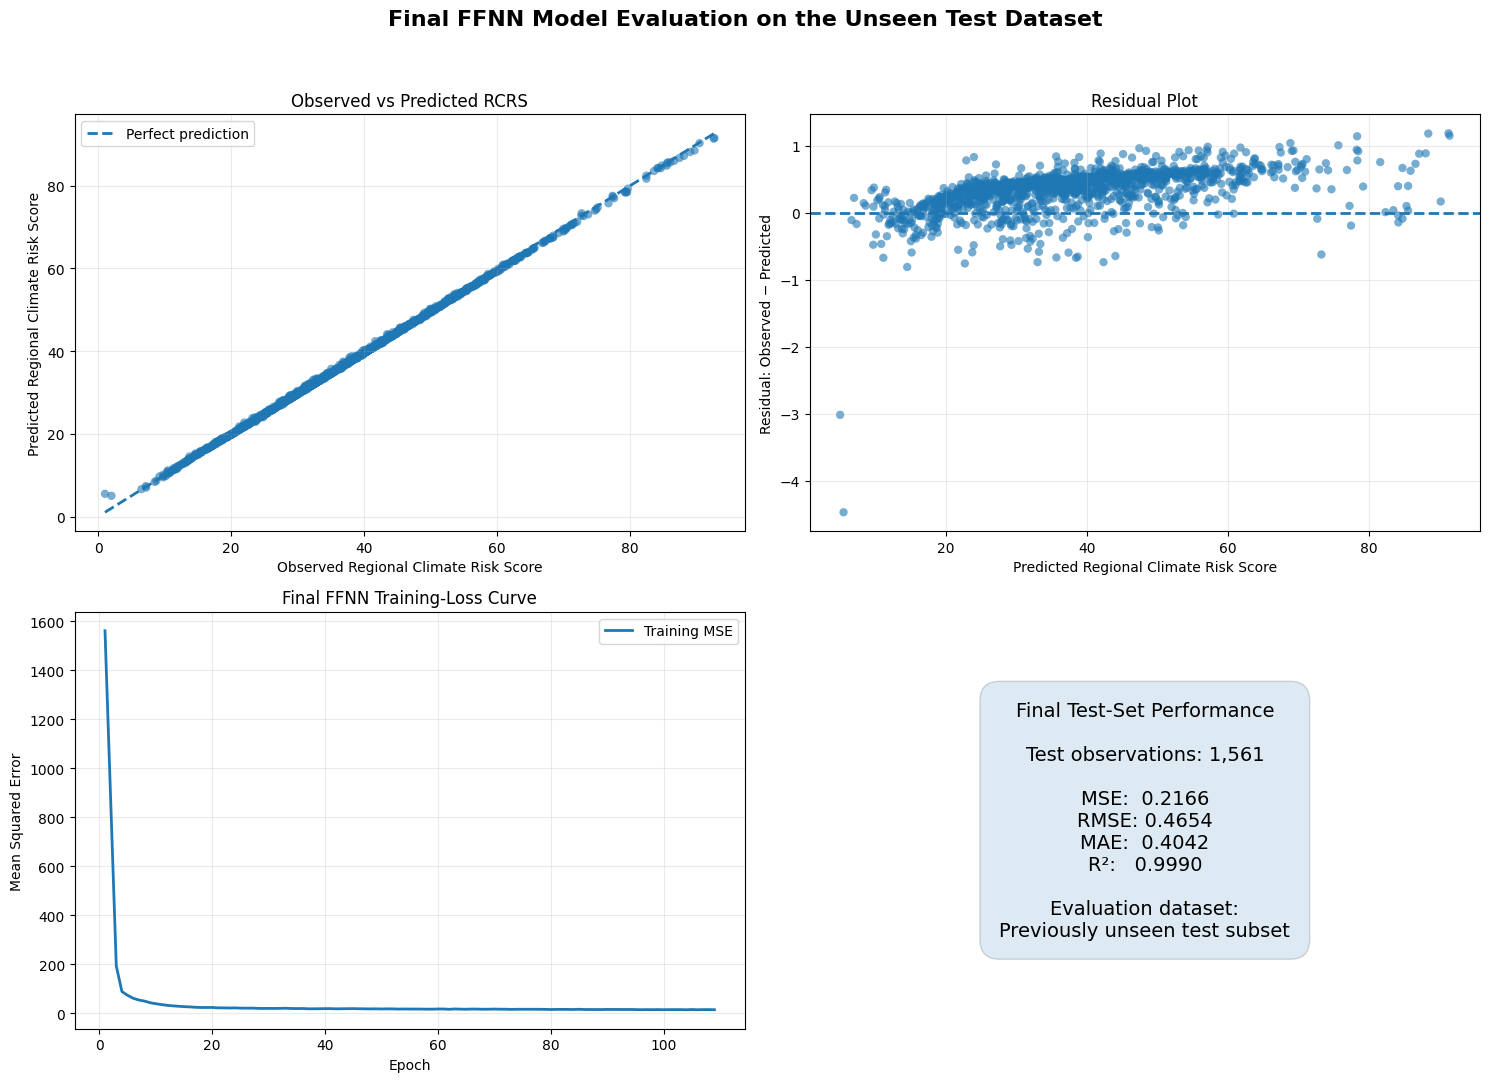

In [49]:
# ============================================================
# Visualize the final FFNN evaluation results
# ============================================================

minimum_score = min(
    y_test_actual.min(),
    y_test_predicted.min()
)

maximum_score = max(
    y_test_actual.max(),
    y_test_predicted.max()
)


# ------------------------------------------------------------
# Create a 2 × 2 evaluation canvas
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(15, 11)
)

fig.suptitle(
    "Final FFNN Model Evaluation on the Unseen Test Dataset",
    fontsize=16,
    fontweight="bold"
)


# ------------------------------------------------------------
# 1. Observed versus predicted RCRS
# ------------------------------------------------------------

axes[0, 0].scatter(
    y_test_actual,
    y_test_predicted,
    alpha=0.60,
    edgecolors="none"
)

axes[0, 0].plot(
    [minimum_score, maximum_score],
    [minimum_score, maximum_score],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

axes[0, 0].set_xlabel(
    "Observed Regional Climate Risk Score"
)

axes[0, 0].set_ylabel(
    "Predicted Regional Climate Risk Score"
)

axes[0, 0].set_title(
    "Observed vs Predicted RCRS"
)

axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)


# ------------------------------------------------------------
# 2. Residual plot
# ------------------------------------------------------------

axes[0, 1].scatter(
    y_test_predicted,
    test_residuals,
    alpha=0.60,
    edgecolors="none"
)

axes[0, 1].axhline(
    y=0,
    linestyle="--",
    linewidth=2
)

axes[0, 1].set_xlabel(
    "Predicted Regional Climate Risk Score"
)

axes[0, 1].set_ylabel(
    "Residual: Observed − Predicted"
)

axes[0, 1].set_title(
    "Residual Plot"
)

axes[0, 1].grid(alpha=0.25)


# ------------------------------------------------------------
# 3. Final-model training-loss curve
# ------------------------------------------------------------

axes[1, 0].plot(
    final_training_history["epoch"],
    final_training_history["training_mse"],
    linewidth=2,
    label="Training MSE"
)

axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Mean Squared Error")

axes[1, 0].set_title(
    "Final FFNN Training-Loss Curve"
)

axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)


# ------------------------------------------------------------
# 4. Final test-performance summary
# ------------------------------------------------------------

axes[1, 1].axis("off")

performance_summary = (
    "Final Test-Set Performance\n\n"
    f"Test observations: {len(y_test_actual):,}\n\n"
    f"MSE:  {test_mse:.4f}\n"
    f"RMSE: {test_rmse:.4f}\n"
    f"MAE:  {test_mae:.4f}\n"
    f"R²:   {test_r2:.4f}\n\n"
    "Evaluation dataset:\n"
    "Previously unseen test subset"
)

axes[1, 1].text(
    0.5,
    0.5,
    performance_summary,
    horizontalalignment="center",
    verticalalignment="center",
    fontsize=14,
    transform=axes[1, 1].transAxes,
    bbox={
        "boxstyle": "round,pad=1",
        "alpha": 0.15
    }
)


# ------------------------------------------------------------
# Final layout
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

### Post-processing: Risk Classification and Sample Predictions

The FFNN predicts the Regional Climate Risk Score (RCRS) as a continuous numerical value. To make these predictions easier to interpret and support practical decision-making, the continuous scores are converted into three ordinal risk categories (Low, Medium, and High) using quantile thresholds derived exclusively from the training target distribution. Computing the thresholds from the training data preserves the independence of the validation and test datasets and prevents information leakage. This section also presents a random sample of district-year observations from the unseen test dataset, allowing the continuous predictions, assigned risk classes, and prediction errors to be inspected before model explainability is performed using SHAP.

##### Calculate training-based quantile thresholds

The thresholds should come from the training target only, not from the test set. That preserves the test set’s independence.

In [50]:
# ============================================================
# Post-process the continuous RCRS predictions
# ============================================================

# ------------------------------------------------------------
# Calculate risk-class thresholds from the training target only
# ------------------------------------------------------------
# The 33rd and 67th percentiles divide the training RCRS
# distribution into Low, Medium, and High risk categories.
#
# The test dataset is not used to determine these thresholds.

training_rcrs = (
    y_train_tensor
    .detach()
    .cpu()
    .numpy()
    .reshape(-1)
)

lower_risk_threshold, upper_risk_threshold = np.quantile(
    training_rcrs,
    [0.33, 0.67]
)


def assign_risk_class(scores):
    """
    Convert continuous RCRS values into three risk classes
    using thresholds derived from the training target.
    """

    return pd.cut(
        scores,
        bins=[
            -np.inf,
            lower_risk_threshold,
            upper_risk_threshold,
            np.inf
        ],
        labels=[
            "Low",
            "Medium",
            "High"
        ],
        include_lowest=True
    )


print("Training-based RCRS classification thresholds:")
print(
    f"  - Low risk:    RCRS ≤ "
    f"{lower_risk_threshold:.4f}"
)
print(
    f"  - Medium risk: "
    f"{lower_risk_threshold:.4f} < RCRS ≤ "
    f"{upper_risk_threshold:.4f}"
)
print(
    f"  - High risk:   RCRS > "
    f"{upper_risk_threshold:.4f}"
)

print(
    "\n✓ Quantile thresholds calculated from the "
    "training target only."
)

Training-based RCRS classification thresholds:
  - Low risk:    RCRS ≤ 31.3718
  - Medium risk: 31.3718 < RCRS ≤ 43.3871
  - High risk:   RCRS > 43.3871

✓ Quantile thresholds calculated from the training target only.


##### Build a test-results dataset

This connects each district-year observation to its observed score, predicted score, residual and final risk class.

In [51]:
# ============================================================
# Create the final test-results dataset
# ============================================================

test_results_df = (
    test_data
    .reset_index(drop=True)
    .copy()
)

# Confirm that the metadata and model outputs are aligned
assert len(test_results_df) == len(y_test_actual), (
    "The test metadata and prediction arrays have "
    "different numbers of observations."
)


# Add continuous evaluation results
test_results_df["observed_rcrs"] = y_test_actual
test_results_df["predicted_rcrs"] = y_test_predicted

test_results_df["prediction_residual"] = (
    test_results_df["observed_rcrs"]
    - test_results_df["predicted_rcrs"]
)

test_results_df["absolute_error"] = np.abs(
    test_results_df["prediction_residual"]
)


# Add post-processed risk classes
test_results_df["observed_risk_class"] = (
    assign_risk_class(
        test_results_df["observed_rcrs"]
    )
)

test_results_df["predicted_risk_class"] = (
    assign_risk_class(
        test_results_df["predicted_rcrs"]
    )
)


# Check whether the predicted and observed classes agree
test_results_df["class_match"] = (
    test_results_df["observed_risk_class"]
    == test_results_df["predicted_risk_class"]
)


class_accuracy = (
    test_results_df["class_match"].mean()
)


print("Post-processing completed successfully:")
print(f"  - Test observations: {len(test_results_df):,}")
print(
    f"  - Risk-class agreement: "
    f"{class_accuracy:.2%}"
)

print("\nPredicted risk-class distribution:")
display(
    test_results_df[
        "predicted_risk_class"
    ]
    .value_counts(sort=False)
    .rename_axis("Risk class")
    .reset_index(name="Observations")
)

Post-processing completed successfully:
  - Test observations: 1,561
  - Risk-class agreement: 97.95%

Predicted risk-class distribution:


,Risk class,Observations
0,Low,547
1,Medium,529
2,High,485


##### Randomly inspect 20 district-year predictions

This code automatically searches for the available district and year columns, so we do not have to guess their exact names.

In [52]:
# ============================================================
# Inspect a random sample of 20 test observations
# ============================================================

sample_size = min(
    20,
    len(test_results_df)
)

sample_results_df = (
    test_results_df
    .sample(
        n=sample_size,
        random_state=TUNING_SEED
    )
    .copy()
)


# ------------------------------------------------------------
# Identify available district and year columns
# ------------------------------------------------------------

district_candidates = [
    "district_name",
    "district",
    "kreis_name",
    "name",
    "target_nuts3_name",
    "nuts3_name",
    "target_ags",
    "ags"
]

year_candidates = [
    "year",
    "Year",
    "reference_year"
]

district_column = next(
    (
        column
        for column in district_candidates
        if column in sample_results_df.columns
    ),
    None
)

year_column = next(
    (
        column
        for column in year_candidates
        if column in sample_results_df.columns
    ),
    None
)


# ------------------------------------------------------------
# Create readable observation labels
# ------------------------------------------------------------

if district_column is not None and year_column is not None:

    sample_results_df["observation_label"] = (
        sample_results_df[district_column].astype(str)
        + " | "
        + sample_results_df[year_column].astype(str)
    )

elif district_column is not None:

    sample_results_df["observation_label"] = (
        sample_results_df[district_column].astype(str)
    )

elif year_column is not None:

    sample_results_df["observation_label"] = (
        "Observation "
        + sample_results_df.index.astype(str)
        + " | "
        + sample_results_df[year_column].astype(str)
    )

else:

    sample_results_df["observation_label"] = (
        "Test observation "
        + sample_results_df.index.astype(str)
    )


# ------------------------------------------------------------
# Select columns for the displayed sample
# ------------------------------------------------------------

sample_display_columns = [
    "observation_label",
    "observed_rcrs",
    "predicted_rcrs",
    "absolute_error",
    "observed_risk_class",
    "predicted_risk_class",
    "class_match"
]


sample_display_df = (
    sample_results_df[
        sample_display_columns
    ]
    .sort_values(
        "predicted_rcrs",
        ascending=False
    )
    .reset_index(drop=True)
)


# Round continuous values for presentation
sample_display_df[
    [
        "observed_rcrs",
        "predicted_rcrs",
        "absolute_error"
    ]
] = sample_display_df[
    [
        "observed_rcrs",
        "predicted_rcrs",
        "absolute_error"
    ]
].round(3)


print(
    "Random sample of 20 district-year test observations:"
)

display(sample_display_df)

Random sample of 20 district-year test observations:


,observation_label,observed_rcrs,predicted_rcrs,absolute_error,observed_risk_class,predicted_risk_class,class_match
0,Ravensburg | 2003,84.731003,84.821999,0.090,High,High,True
1,Main-Taunus-Kreis | 2003,72.688004,73.311996,0.624,High,High,True
2,Spree-Neiße | 1993,51.709000,51.200001,0.509,High,High,True
3,Kelheim | 1995,46.790001,46.567001,0.222,High,High,True
4,Oberspreewald-Lausitz | 2005,46.599998,46.087002,0.513,High,High,True
5,Neumarkt i. d. OPf. | 1995,42.491001,42.143002,0.348,Medium,Medium,True
6,Rhein-Neckar-Kreis | 2006,40.730000,40.198002,0.532,Medium,Medium,True
7,Gotha | 1999,40.619999,40.118999,0.501,Medium,Medium,True
8,"Pirmasens, Kreisfreie Stadt | 2002",38.126999,37.655998,0.472,Medium,Medium,True
9,Minden-Lübbecke | 2011,31.216999,31.327000,0.109,Low,Low,True


##### Visualize the 20 sampled scores

This compares the observed and predicted scores while also showing the assigned predicted class.

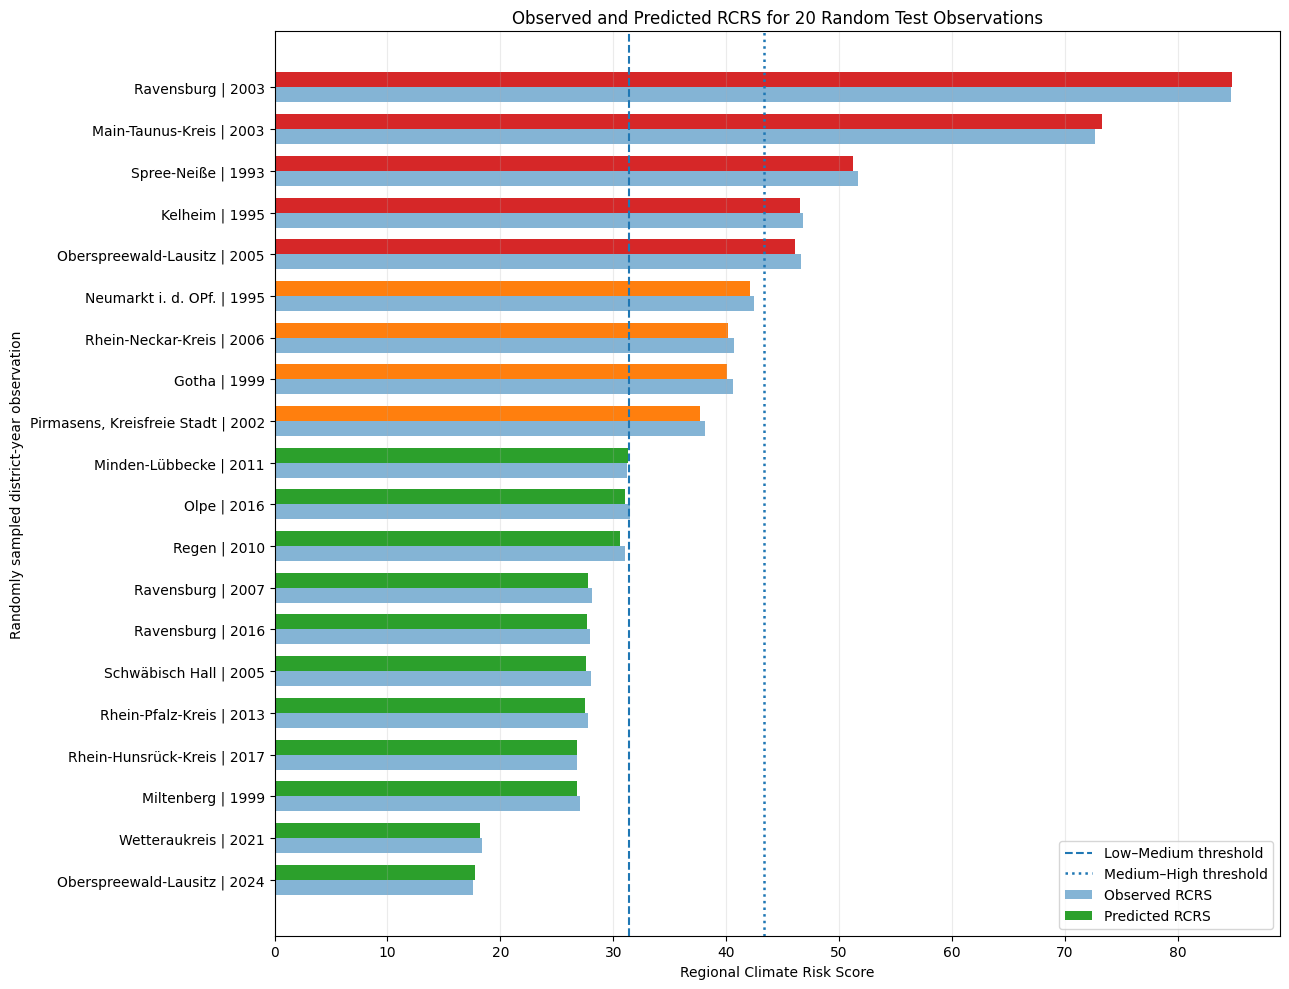

In [53]:
# ============================================================
# Visualize 20 randomly sampled district-year predictions
# ============================================================

sample_plot_df = (
    sample_results_df
    .sort_values(
        "predicted_rcrs",
        ascending=True
    )
    .reset_index(drop=True)
)


risk_class_colours = {
    "Low": "tab:green",
    "Medium": "tab:orange",
    "High": "tab:red"
}

predicted_colours = (
    sample_plot_df["predicted_risk_class"]
    .astype(str)
    .map(risk_class_colours)
)


y_positions = np.arange(
    len(sample_plot_df)
)

bar_height = 0.36


fig, ax = plt.subplots(
    figsize=(13, 10)
)


# Observed scores
ax.barh(
    y_positions - bar_height / 2,
    sample_plot_df["observed_rcrs"],
    height=bar_height,
    label="Observed RCRS",
    alpha=0.55
)


# Predicted scores, coloured by assigned risk class
ax.barh(
    y_positions + bar_height / 2,
    sample_plot_df["predicted_rcrs"],
    height=bar_height,
    color=predicted_colours,
    label="Predicted RCRS"
)


# Quantile thresholds
ax.axvline(
    lower_risk_threshold,
    linestyle="--",
    linewidth=1.5,
    label="Low–Medium threshold"
)

ax.axvline(
    upper_risk_threshold,
    linestyle=":",
    linewidth=1.8,
    label="Medium–High threshold"
)


ax.set_yticks(y_positions)

ax.set_yticklabels(
    sample_plot_df["observation_label"]
)

ax.set_xlabel(
    "Regional Climate Risk Score"
)

ax.set_ylabel(
    "Randomly sampled district-year observation"
)

ax.set_title(
    "Observed and Predicted RCRS for 20 Random Test Observations"
)

ax.grid(
    axis="x",
    alpha=0.25
)

ax.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()

### Model Explainability and Interpretation Using SHAP

Although the Feed-Forward Neural Network (FFNN) achieved excellent predictive performance, neural networks are often regarded as "black-box" models because their internal decision-making process is not directly interpretable. To improve transparency and support responsible AI, SHAP (SHapley Additive exPlanations) was applied to explain the predictions generated by the trained FFNN.

SHAP provides both local and global model explanations. Local explanations quantify how each predictor contributes to the predicted Regional Climate Risk Score (RCRS) for an individual district, whereas global explanations identify the overall importance and behaviour of predictors across all explained observations. Together, these analyses improve the transparency, interpretability, and scientific defensibility of the proposed AI-powered Regional Climate Risk Intelligence framework.

**Computational note:** To balance interpretability and computational efficiency, SHAP explanations were generated using a reproducible random sample of 200 observations from the independent test dataset. This sampling affects only the explainability analysis; model training and evaluation were performed using the complete training, validation, and test datasets.

##### Compute SHAP Values

In [54]:
# Inspect relevant objects currently available in the notebook
for name in sorted(globals()):
    if any(
        keyword in name.lower()
        for keyword in ["train", "test", "model", "feature"]
    ):
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"{name:<35} type={type(obj).__name__:<20} shape={shape}")

MODEL_DIR                           type=WindowsPath          shape=None
X_final_train_tensor                type=Tensor               shape=torch.Size([8843, 5])
X_test_device                       type=Tensor               shape=torch.Size([1561, 5])
X_test_df                           type=DataFrame            shape=(1561, 5)
X_test_processed                    type=ndarray              shape=(1561, 5)
X_test_raw                          type=DataFrame            shape=(1561, 5)
X_test_tensor                       type=Tensor               shape=torch.Size([1561, 5])
X_train_df                          type=DataFrame            shape=(7282, 5)
X_train_processed                   type=ndarray              shape=(7282, 5)
X_train_raw                         type=DataFrame            shape=(7282, 5)
X_train_tensor                      type=Tensor               shape=torch.Size([7282, 5])
all_models                          type=list                 shape=None
average_training_mae      

In [56]:
# ============================================================
# Compute SHAP values for the trained PyTorch FFNN
# ============================================================

# Ensure reproducible SHAP sampling
rng = np.random.default_rng(42)

# Retrieve the five predictor names from the training DataFrame
feature_names = X_train_df.columns.tolist()

# Convert the processed datasets to NumPy arrays
X_train_shap = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_test_shap = np.asarray(
    X_test_processed,
    dtype=np.float32
)

# ------------------------------------------------------------
# Select a representative training background sample
# ------------------------------------------------------------

background_size = min(200, len(X_train_shap))

background_indices = rng.choice(
    len(X_train_shap),
    size=background_size,
    replace=False
)

shap_background_values = X_train_shap[background_indices]

# ------------------------------------------------------------
# Select test observations to explain
# ------------------------------------------------------------

n_explanations = min(200, len(X_test_shap))

explanation_indices = rng.choice(
    len(X_test_shap),
    size=n_explanations,
    replace=False
)

shap_input_values = X_test_shap[explanation_indices]

# ------------------------------------------------------------
# Convert the SHAP samples to PyTorch tensors
# ------------------------------------------------------------

model_device = next(final_model.parameters()).device

background_tensor = torch.tensor(
    shap_background_values,
    dtype=torch.float32,
    device=model_device
)

explanation_tensor = torch.tensor(
    shap_input_values,
    dtype=torch.float32,
    device=model_device
)

# Place the final model in evaluation mode
final_model.eval()

# ------------------------------------------------------------
# Create the SHAP DeepExplainer
# ------------------------------------------------------------

explainer = shap.DeepExplainer(
    final_model,
    background_tensor
)

# Calculate SHAP values for the selected test observations
shap_values_raw = explainer.shap_values(
    explanation_tensor
)

# ------------------------------------------------------------
# Standardize the returned SHAP array
# ------------------------------------------------------------

# Some SHAP versions return a list for single-output models
if isinstance(shap_values_raw, list):
    shap_values = np.asarray(shap_values_raw[0])
else:
    shap_values = np.asarray(shap_values_raw)

# Remove a final single-output dimension where present
if shap_values.ndim == 3 and shap_values.shape[-1] == 1:
    shap_values = shap_values[:, :, 0]

# Retrieve the SHAP baseline value
expected_value_raw = np.asarray(explainer.expected_value).reshape(-1)
expected_value = float(expected_value_raw[0])

print("SHAP values successfully computed.")
print(f"Background observations: {len(shap_background_values):,}")
print(f"Explained observations:  {len(shap_input_values):,}")
print(f"SHAP values shape:       {shap_values.shape}")
print(f"Baseline RCRS value:     {expected_value:.4f}")
print(f"Feature names:           {feature_names}")

SHAP values successfully computed.
Background observations: 200
Explained observations:  200
SHAP values shape:       (200, 5)
Baseline RCRS value:     39.6613
Feature names:           ['heatwave', 'flood', 'drought', 'gdp_per_capita', 'unemployment_rate']


Local SHAP explanation:
  - Observation: Heilbronn, Stadtkreis
  - Predicted RCRS: 82.4098
  - SHAP baseline value: 39.6613


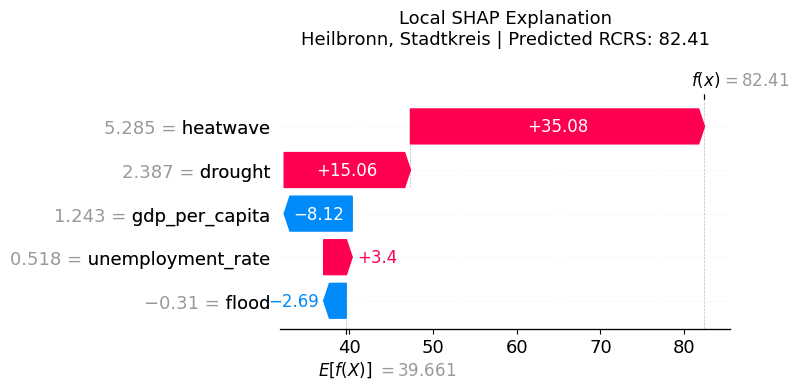

In [61]:
# ============================================================
# Local SHAP explanation using a waterfall plot
# ============================================================

# Retrieve predictions corresponding to the explained subset

explained_predictions = y_test_predicted[
    explanation_indices
]


# Select the highest predicted RCRS within the explained sample

local_position = int(
    np.argmax(explained_predictions)
)

original_test_index = int(
    explanation_indices[local_position].item()
)


# Create a SHAP Explanation object for the selected observation

local_explanation = shap.Explanation(
    values=shap_values[local_position],
    base_values=expected_value,
    data=shap_input_values[local_position],
    feature_names=feature_names
)


# ------------------------------------------------------------
# Retrieve the readable district label
# ------------------------------------------------------------

if "test_results_df" not in globals():
    raise NameError(
        "test_results_df is not available. "
        "Cannot retrieve the district label."
    )

if "district_name" not in test_results_df.columns:
    raise KeyError(
        "'district_name' was not found in test_results_df. "
        f"Available columns: {test_results_df.columns.tolist()}"
    )

local_observation_label = str(
    test_results_df.iloc[
        original_test_index
    ]["district_name"]
)

local_prediction = float(
    explained_predictions[local_position]
)


print("Local SHAP explanation:")
print(f"  - Observation: {local_observation_label}")
print(f"  - Predicted RCRS: {local_prediction:.4f}")
print(f"  - SHAP baseline value: {expected_value:.4f}")


# ------------------------------------------------------------
# Display the waterfall plot
# ------------------------------------------------------------

shap.plots.waterfall(
    local_explanation,
    max_display=len(feature_names),
    show=False
)

plt.title(
    f"Local SHAP Explanation\n"
    f"{local_observation_label} | Predicted RCRS: "
    f"{local_prediction:.2f}",
    fontsize=13,
    pad=18
)

plt.tight_layout()
plt.show()

In [60]:
print(test_results_df.columns.tolist())

['district_code', 'district_name', 'year', 'heatwave', 'flood', 'drought', 'gdp_per_capita', 'unemployment_rate', 'rcrs', 'observed_rcrs', 'predicted_rcrs', 'prediction_residual', 'absolute_error', 'observed_risk_class', 'predicted_risk_class', 'class_match']


**Interpretation** The waterfall plot explains how the FFNN generated the predicted Regional Climate Risk Score (RCRS) for Heilbronn, Stadtkreis. Starting from the average baseline prediction of 39.66, the exceptionally high heatwave frequency makes the largest positive contribution (+35.08), followed by drought magnitude (+15.06). Unemployment rate also increases the predicted risk, although its contribution is comparatively smaller (+3.40). In contrast, GDP per capita (-8.12) and flood intensity (-2.69) reduce the predicted risk, partially offsetting the effects of the other variables. The combined contributions produce a final predicted RCRS of 82.41, illustrating how the FFNN integrates both climatic hazards and socioeconomic conditions to generate transparent, observation-specific climate risk

##### Baseline vs Average Prediction

Explain what the SHAP baseline represents and compare it with the
average prediction across the explained observations.

In [65]:
# ============================================================
# Compare the SHAP baseline with the average model prediction
# ============================================================
#
# baseline:
#     The SHAP expected value. It represents the average RCRS
#     predicted by the FFNN for the SHAP background dataset
#     before any observation-specific feature contributions
#     are considered.
#
# average_prediction:
#     The mean predicted RCRS across the 200 explained test
#     observations.
#
# difference:
#     Indicates whether the explained test sample has, on
#     average, a higher or lower predicted RCRS than the SHAP
#     background reference population.
# ============================================================

baseline = float(expected_value)

average_prediction = float(
    np.mean(explained_predictions)
)

difference = average_prediction - baseline

print("SHAP baseline and average prediction:")
print(f"  - SHAP baseline RCRS:              {baseline:.4f}")
print(f"  - Average predicted RCRS (n=200):  {average_prediction:.4f}")
print(f"  - Difference from baseline:        {difference:+.4f}")

if difference > 0:
    print(
        "  - Interpretation: The explained test sample has a "
        "higher average predicted RCRS than the SHAP background."
    )
elif difference < 0:
    print(
        "  - Interpretation: The explained test sample has a "
        "lower average predicted RCRS than the SHAP background."
    )
else:
    print(
        "  - Interpretation: The explained sample average is "
        "equal to the SHAP baseline."
    )

SHAP baseline and average prediction:
  - SHAP baseline RCRS:              39.6613
  - Average predicted RCRS (n=200):  36.5004
  - Difference from baseline:        -3.1609
  - Interpretation: The explained test sample has a lower average predicted RCRS than the SHAP background.


**Interpretation:** The SHAP baseline is the FFNN's expected Regional Climate Risk Score for the background reference dataset before the characteristics of a particular district are considered. The average prediction is calculated separately from the 200 test observations selected for SHAP explanation. Their difference indicates whether the explained sample is, on average, predicted to have a higher or lower climate risk than the background reference population. The baseline is therefore a model reference value and should not be interpreted as the risk score of a specific district or as evidence that most districts belong to a particular risk class.

##### Global SHAP Feature Importance

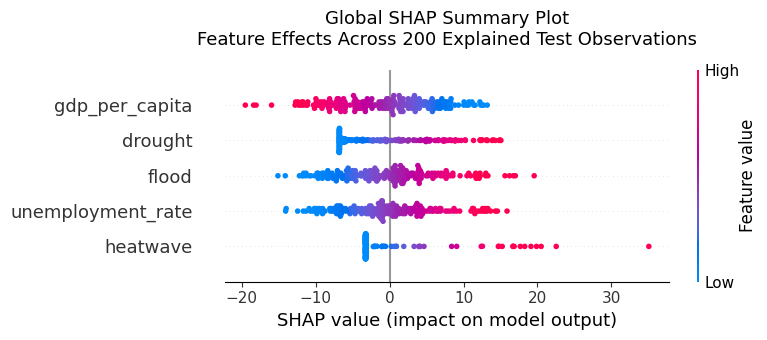

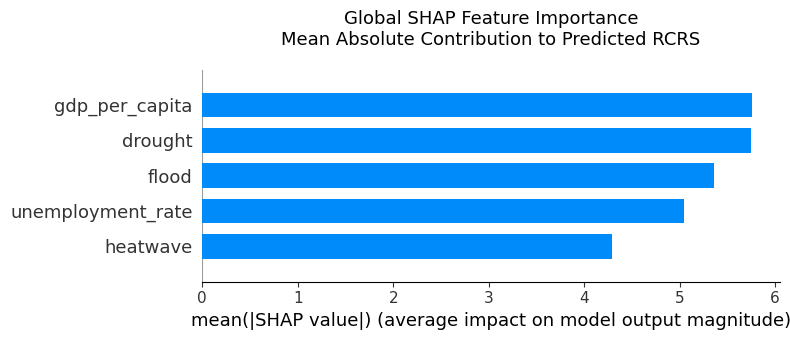

Global SHAP plots successfully generated and saved.
  - Beeswarm plot: reports\figures\shap\shap_global_summary_beeswarm.png
  - Bar plot:      reports\figures\shap\shap_global_feature_importance_bar.png


,feature,mean_absolute_shap_value
1,gdp_per_capita,5.758605
2,drought,5.748447
3,flood,5.356077
4,unemployment_rate,5.049468
5,heatwave,4.292976


In [66]:
# ============================================================
# Global SHAP Feature Importance
# ============================================================
#
# The beeswarm plot shows both the magnitude and direction of
# each feature's influence across the 200 explained observations.
#
# The bar plot ranks predictors using their mean absolute SHAP
# values and therefore shows overall model-wide importance.
# ============================================================

from pathlib import Path

SHAP_FIGURE_DIR = Path("reports/figures/shap")
SHAP_FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. SHAP summary plot — beeswarm
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values,
    shap_input_values,
    feature_names=feature_names,
    plot_type="dot",
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Global SHAP Summary Plot\n"
    "Feature Effects Across 200 Explained Test Observations",
    fontsize=13,
    pad=18
)

plt.tight_layout()

beeswarm_path = (
    SHAP_FIGURE_DIR /
    "shap_global_summary_beeswarm.png"
)

plt.savefig(
    beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 2. SHAP global feature-importance bar plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

shap.summary_plot(
    shap_values,
    shap_input_values,
    feature_names=feature_names,
    plot_type="bar",
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Global SHAP Feature Importance\n"
    "Mean Absolute Contribution to Predicted RCRS",
    fontsize=13,
    pad=18
)

plt.tight_layout()

bar_path = (
    SHAP_FIGURE_DIR /
    "shap_global_feature_importance_bar.png"
)

plt.savefig(
    bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 3. Display numerical global importance ranking
# ------------------------------------------------------------

mean_absolute_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

global_importance_df = (
    pd.DataFrame({
        "feature": feature_names,
        "mean_absolute_shap_value": mean_absolute_shap
    })
    .sort_values(
        "mean_absolute_shap_value",
        ascending=False
    )
    .reset_index(drop=True)
)

global_importance_df.index = (
    global_importance_df.index + 1
)

print("Global SHAP plots successfully generated and saved.")
print(f"  - Beeswarm plot: {beeswarm_path}")
print(f"  - Bar plot:      {bar_path}")

display(global_importance_df)

**Interpretation:** The beeswarm plot provides a global view of how the five predictors influence FFNN predictions across the 200 explained test observations. Each point represents one observation. Its horizontal position indicates whether the feature increases or decreases the predicted RCRS, while its colour represents a relatively high or low processed feature value. The bar plot presents the corresponding overall importance ranking based on mean absolute SHAP values. Because absolute values are used, the bar plot measures the average magnitude of influence but does not indicate whether a feature generally increases or decreases risk. Global importance can therefore differ from the local Heilbronn explanation: a predictor may be highly influential for one district without being the most influential predictor across the full explained sample.

##### Global SHAP Waterfall

Average global SHAP explanation:
  - SHAP baseline RCRS:                39.6613
  - Average predicted RCRS:            36.5004
  - SHAP-reconstructed average RCRS:   36.5004
  - Numerical reconstruction difference: +0.00000078


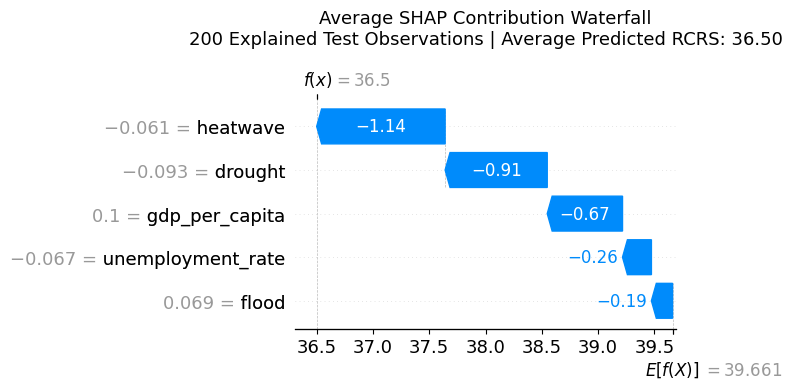

Global aggregate waterfall saved to: reports\figures\shap\shap_average_global_waterfall.png


,feature,mean_processed_feature_value,mean_signed_shap_contribution,mean_absolute_shap_value,absolute_mean_signed_contribution
0,heatwave,-0.061188,-1.140858,4.292976,1.140858
1,drought,-0.093383,-0.907050,5.748447,0.907050
2,gdp_per_capita,0.100475,-0.668611,5.758605,0.668611
3,unemployment_rate,-0.067386,-0.256657,5.049468,0.256657
4,flood,0.069129,-0.187737,5.356077,0.187737


In [67]:
# ============================================================
# Average SHAP Contribution Waterfall — Global Aggregate
# ============================================================
#
# A standard SHAP waterfall explains one observation. The plot
# below is a custom global aggregate constructed from the mean
# signed SHAP contribution of each feature across the 200
# explained test observations.
#
# It starts from the same SHAP baseline and ends at the average
# prediction of the explained sample:
#
# average prediction
#     = SHAP baseline
#     + sum of mean signed SHAP contributions
#
# Unlike the mean absolute SHAP bar plot, signed mean SHAP
# contributions retain direction and may cancel one another.
# ============================================================

# Calculate the mean signed contribution of each feature
mean_signed_shap = np.mean(
    shap_values,
    axis=0
)

# Calculate average processed feature values for display
mean_processed_values = np.mean(
    shap_input_values,
    axis=0
)

# Reconstruct the average prediction through SHAP additivity
shap_reconstructed_average = float(
    baseline + np.sum(mean_signed_shap)
)

# Difference between the directly calculated and reconstructed means
reconstruction_difference = float(
    average_prediction - shap_reconstructed_average
)

# Create an aggregate SHAP Explanation object
global_average_explanation = shap.Explanation(
    values=mean_signed_shap,
    base_values=baseline,
    data=mean_processed_values,
    feature_names=feature_names
)

print("Average global SHAP explanation:")
print(f"  - SHAP baseline RCRS:                {baseline:.4f}")
print(f"  - Average predicted RCRS:            {average_prediction:.4f}")
print(f"  - SHAP-reconstructed average RCRS:   {shap_reconstructed_average:.4f}")
print(f"  - Numerical reconstruction difference: {reconstruction_difference:+.8f}")


# ------------------------------------------------------------
# Display and save the aggregate waterfall plot
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

shap.plots.waterfall(
    global_average_explanation,
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Average SHAP Contribution Waterfall\n"
    f"200 Explained Test Observations | "
    f"Average Predicted RCRS: {average_prediction:.2f}",
    fontsize=13,
    pad=18
)

plt.tight_layout()

global_waterfall_path = (
    SHAP_FIGURE_DIR /
    "shap_average_global_waterfall.png"
)

plt.savefig(
    global_waterfall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Numerical table of average signed SHAP contributions
# ------------------------------------------------------------

global_contribution_df = pd.DataFrame({
    "feature": feature_names,
    "mean_processed_feature_value": mean_processed_values,
    "mean_signed_shap_contribution": mean_signed_shap,
    "mean_absolute_shap_value": mean_absolute_shap
})

global_contribution_df[
    "absolute_mean_signed_contribution"
] = (
    global_contribution_df[
        "mean_signed_shap_contribution"
    ].abs()
)

global_contribution_df = (
    global_contribution_df
    .sort_values(
        "absolute_mean_signed_contribution",
        ascending=False
    )
    .reset_index(drop=True)
)

print(f"Global aggregate waterfall saved to: {global_waterfall_path}")

display(global_contribution_df)

**Interpretation:** This custom aggregate waterfall complements the local Heilbronn waterfall by summarising the model's average behaviour across the 200 explained test observations. It begins at the SHAP baseline and applies the mean signed SHAP contribution of each predictor until the average predicted RCRS of the explained sample is reached. Positive contributions move the explained-sample average above the baseline, while negative contributions move it below the baseline.

This plot should be distinguished from the global mean absolute SHAP bar plot. The bar plot ranks features according to the average magnitude of their influence, regardless of direction. The aggregate waterfall instead uses signed mean contributions; positive and negative effects across different observations can therefore cancel each other. Consequently, a feature may have high global importance in the bar plot but a comparatively small average signed contribution in the aggregate waterfall.

### Local and Global SHAP Comparison

The local and global SHAP explanations answer different but complementary questions:

| Explanation | Main question | Reference point | Final value |
|---|---|---|---|
| Local waterfall | Why did the model generate this prediction for Heilbronn, Stadtkreis? | SHAP baseline | Heilbronn's predicted RCRS |
| Global beeswarm | How do feature values influence predictions across the explained observations? | Zero SHAP contribution | Distribution of positive and negative effects |
| Global bar plot | Which predictors have the greatest average influence overall? | Mean absolute SHAP value | Global feature-importance ranking |
| Average aggregate waterfall | How do average signed feature contributions move the explained sample away from the baseline? | SHAP baseline | Average predicted RCRS of the explained sample |

**Key Explainability Insight:** The FFNN is interpretable at both the local and global levels. The Heilbronn waterfall identifies the factors responsible for one high-risk prediction, whereas the global plots reveal model-wide feature behaviour and importance across the explained sample. Together, the results demonstrate that the model combines climatic hazards and socioeconomic conditions in a transparent and scientifically defensible manner.

### Save the Complete FFNN Pipeline + SHAP Artifacts

Local SHAP explanation:
  - Observation: Test observation 1416
  - Predicted RCRS: 82.4098
  - SHAP baseline value: 39.6613


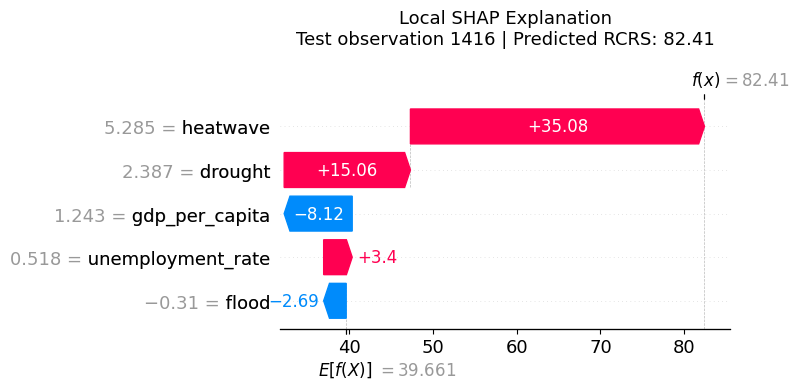


COMPLETE AI PIPELINE SAVING REPORT

Successfully saved:
  [OK] models\feature_columns.json
  [OK] models\final_ffnn_state_dict.pt
  [OK] models\final_ffnn_model.pth
  [OK] models\model_architecture.txt
  [OK] models\target_scaler.joblib
  [OK] models\preprocessing_pipeline.pkl
  [OK] models\hyperparameters.json
  [OK] models\model_configuration.json
  [OK] models\training_history.json
  [OK] models\performance_metrics.json
  [OK] models\model_metadata.json
  [OK] models\test_predictions.csv
  [OK] models\shap\shap_values.npy
  [OK] models\shap\shap_input_values.npy
  [OK] models\shap\shap_background_values.npy
  [OK] models\shap\shap_explanation_indices.npy
  [OK] models\shap\shap_metadata.json
  [OK] models\shap\global_shap_feature_importance.csv
  [OK] reports\figures\shap\shap_waterfall_highest_predicted_rcrs.png
  [OK] models\shap\local_shap_explanation_highest_risk.csv
  [OK] models\artifact_manifest.json

Not saved or not yet applicable:
  [INFO] Feature scaler: no recognised sc

,feature,mean_absolute_shap_value
0,gdp_per_capita,5.758605
1,drought,5.748447
2,flood,5.356077
3,unemployment_rate,5.049468
4,heatwave,4.292976


,observation,original_test_index,predicted_rcrs,baseline_rcrs,feature,processed_feature_value,shap_contribution,absolute_shap_contribution
0,Test observation 1416,1416,82.409836,39.661278,heatwave,5.285262,35.083389,35.083389
1,Test observation 1416,1416,82.409836,39.661278,drought,2.387194,15.064337,15.064337
2,Test observation 1416,1416,82.409836,39.661278,gdp_per_capita,1.242947,-8.117049,8.117049
3,Test observation 1416,1416,82.409836,39.661278,unemployment_rate,0.517511,3.404559,3.404559
4,Test observation 1416,1416,82.409836,39.661278,flood,-0.309835,-2.686675,2.686675


In [59]:
# ============================================================
# SAVE THE COMPLETE FFNN PIPELINE + SHAP ARTIFACTS
# ============================================================

from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import shap


# ------------------------------------------------------------
# 1. Create output directories
# ------------------------------------------------------------

MODEL_DIR = Path("models")
SHAP_DIR = MODEL_DIR / "shap"
FIGURE_DIR = Path("reports/figures/shap")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
SHAP_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def make_json_serializable(value):
    """Convert common NumPy, pandas and PyTorch objects to JSON-safe values."""

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy().tolist()

    if isinstance(value, pd.Series):
        return value.to_dict()

    if isinstance(value, pd.DataFrame):
        return value.to_dict(orient="records")

    if isinstance(value, dict):
        return {
            str(key): make_json_serializable(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_serializable(item)
            for item in value
        ]

    if value is None or isinstance(
        value,
        (str, int, float, bool)
    ):
        return value

    return str(value)


def save_json(data, output_path):
    """Save an object as formatted JSON."""

    with open(
        output_path,
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(
            make_json_serializable(data),
            file,
            indent=4,
            ensure_ascii=False
        )


def find_first_existing_object(candidate_names):
    """Return the first available notebook object and its name."""

    for candidate_name in candidate_names:
        if candidate_name in globals():
            return candidate_name, globals()[candidate_name]

    return None, None


saved_files = []
skipped_items = []


# ------------------------------------------------------------
# 3. Confirm the model and feature names
# ------------------------------------------------------------

if "final_model" not in globals():
    raise NameError(
        "final_model was not found. Run the final-model training cell first."
    )

if "feature_names" in globals():
    saved_feature_names = list(feature_names)

elif "X_train_df" in globals():
    saved_feature_names = X_train_df.columns.tolist()

else:
    saved_feature_names = [
        "heatwave",
        "flood",
        "drought",
        "gdp_per_capita",
        "unemployment_rate"
    ]


# ------------------------------------------------------------
# 4. Save feature order
# ------------------------------------------------------------

feature_columns_path = (
    MODEL_DIR /
    "feature_columns.json"
)

save_json(
    {
        "feature_columns": saved_feature_names,
        "feature_count": len(saved_feature_names)
    },
    feature_columns_path
)

saved_files.append(feature_columns_path)


# ------------------------------------------------------------
# 5. Save the trained PyTorch FFNN
# ------------------------------------------------------------

final_model.eval()

model_state_path = (
    MODEL_DIR /
    "final_ffnn_state_dict.pt"
)

torch.save(
    final_model.state_dict(),
    model_state_path
)

saved_files.append(model_state_path)


# Retrieve optimizer where available
optimizer_name, optimizer_object = find_first_existing_object([
    "final_optimizer",
    "best_optimizer",
    "optimizer"
])


# Complete deployment checkpoint
checkpoint = {
    "model_class": final_model.__class__.__name__,
    "model_state_dict": final_model.state_dict(),
    "feature_names": saved_feature_names,
    "input_dimension": len(saved_feature_names),
    "output_dimension": 1,
    "target_name": "Regional Climate Risk Score",
    "target_abbreviation": "RCRS",
    "model_architecture": str(final_model),
    "random_seed": 42
}

if optimizer_object is not None and hasattr(
    optimizer_object,
    "state_dict"
):
    checkpoint["optimizer_name"] = optimizer_name
    checkpoint["optimizer_state_dict"] = (
        optimizer_object.state_dict()
    )

model_checkpoint_path = (
    MODEL_DIR /
    "final_ffnn_model.pth"
)

torch.save(
    checkpoint,
    model_checkpoint_path
)

saved_files.append(model_checkpoint_path)


# Save readable architecture
architecture_path = (
    MODEL_DIR /
    "model_architecture.txt"
)

with open(
    architecture_path,
    "w",
    encoding="utf-8"
) as file:
    file.write(str(final_model))

saved_files.append(architecture_path)


# ------------------------------------------------------------
# 6. Save scaler(s) and preprocessing pipeline
# ------------------------------------------------------------

feature_scaler_name, feature_scaler = (
    find_first_existing_object([
        "feature_scaler",
        "input_scaler",
        "scaler",
        "standard_scaler",
        "x_scaler"
    ])
)

if feature_scaler is not None:

    feature_scaler_path = (
        MODEL_DIR /
        "feature_scaler.joblib"
    )

    joblib.dump(
        feature_scaler,
        feature_scaler_path
    )

    saved_files.append(feature_scaler_path)

else:
    skipped_items.append(
        "Feature scaler: no recognised scaler object was found."
    )


target_scaler_name, target_scaler = (
    find_first_existing_object([
        "target_scaler",
        "y_scaler",
        "rcrs_scaler"
    ])
)

if target_scaler is not None:

    target_scaler_path = (
        MODEL_DIR /
        "target_scaler.joblib"
    )

    joblib.dump(
        target_scaler,
        target_scaler_path
    )

    saved_files.append(target_scaler_path)

else:
    skipped_items.append(
        "Target scaler: not found or not applicable."
    )


pipeline_name, preprocessing_pipeline = (
    find_first_existing_object([
        "preprocessing_pipeline",
        "feature_pipeline",
        "rcrs_pipeline",
        "pipeline"
    ])
)

if preprocessing_pipeline is not None:

    preprocessing_pipeline_path = (
        MODEL_DIR /
        "preprocessing_pipeline.pkl"
    )

    with open(
        preprocessing_pipeline_path,
        "wb"
    ) as file:
        pickle.dump(
            preprocessing_pipeline,
            file
        )

    saved_files.append(
        preprocessing_pipeline_path
    )

else:
    skipped_items.append(
        "Preprocessing pipeline: no combined pipeline object was found."
    )


# ------------------------------------------------------------
# 7. Save hyperparameters and model configuration
# ------------------------------------------------------------

hyperparameter_names = [
    "best_hyperparameters",
    "best_params",
    "final_hyperparameters",
    "hyperparameters"
]

hyperparameter_object_name, hyperparameter_object = (
    find_first_existing_object(
        hyperparameter_names
    )
)

if hyperparameter_object is None:
    hyperparameter_object = {}


# Add independently defined training settings where available
training_setting_candidates = [
    "BATCH_SIZE",
    "LEARNING_RATE",
    "PATIENCE",
    "MIN_DELTA",
    "MAX_EPOCHS",
    "RANDOM_SEED",
    "WEIGHT_DECAY",
    "DROPOUT_RATE"
]

for setting_name in training_setting_candidates:
    if setting_name in globals():
        hyperparameter_object[setting_name.lower()] = (
            globals()[setting_name]
        )


hyperparameters_path = (
    MODEL_DIR /
    "hyperparameters.json"
)

save_json(
    hyperparameter_object,
    hyperparameters_path
)

saved_files.append(hyperparameters_path)


model_configuration = {
    "framework": "PyTorch",
    "model_class": final_model.__class__.__name__,
    "architecture": str(final_model),
    "input_variables": saved_feature_names,
    "input_dimension": len(saved_feature_names),
    "output_dimension": 1,
    "target_variable": "Regional Climate Risk Score",
    "target_abbreviation": "RCRS",
    "task_type": "regression",
    "loss_function": (
        str(globals().get("criterion", "MSE loss"))
    ),
    "optimizer": (
        optimizer_object.__class__.__name__
        if optimizer_object is not None
        else "Not detected"
    ),
    "feature_scaler_object": feature_scaler_name,
    "target_scaler_object": target_scaler_name,
    "preprocessing_pipeline_object": pipeline_name,
    "hyperparameter_object": hyperparameter_object_name,
    "random_seed": int(
        globals().get("RANDOM_SEED", 42)
    )
}

model_configuration_path = (
    MODEL_DIR /
    "model_configuration.json"
)

save_json(
    model_configuration,
    model_configuration_path
)

saved_files.append(model_configuration_path)


# ------------------------------------------------------------
# 8. Save training history
# ------------------------------------------------------------

history_name, training_history = (
    find_first_existing_object([
        "final_training_history",
        "best_training_history",
        "training_history",
        "history"
    ])
)

if training_history is not None:

    training_history_path = (
        MODEL_DIR /
        "training_history.json"
    )

    save_json(
        training_history,
        training_history_path
    )

    saved_files.append(training_history_path)

else:
    skipped_items.append(
        "Training history: no recognised history object was found."
    )


# ------------------------------------------------------------
# 9. Save performance metrics
# ------------------------------------------------------------

metric_candidates = [
    "final_test_mse",
    "final_test_rmse",
    "final_test_mae",
    "final_test_r2",
    "test_mse",
    "test_rmse",
    "test_mae",
    "test_r2",
    "best_test_mse",
    "best_test_rmse",
    "best_test_mae",
    "best_test_r2",
    "final_training_mse",
    "final_training_rmse",
    "final_training_mae",
    "average_training_mse",
    "average_training_rmse",
    "average_training_mae"
]

performance_metrics = {}

for metric_name in metric_candidates:
    if metric_name in globals():
        performance_metrics[metric_name] = (
            globals()[metric_name]
        )


# Derive final test metrics where predictions and targets exist
if (
    "y_test_predicted" in globals()
    and "y_test" in globals()
):

    from sklearn.metrics import (
        mean_absolute_error,
        mean_squared_error,
        r2_score
    )

    y_true_for_saving = np.asarray(
        y_test
    ).reshape(-1)

    y_pred_for_saving = np.asarray(
        y_test_predicted
    ).reshape(-1)

    calculated_mse = mean_squared_error(
        y_true_for_saving,
        y_pred_for_saving
    )

    performance_metrics.update({
        "calculated_test_mse": float(
            calculated_mse
        ),
        "calculated_test_rmse": float(
            np.sqrt(calculated_mse)
        ),
        "calculated_test_mae": float(
            mean_absolute_error(
                y_true_for_saving,
                y_pred_for_saving
            )
        ),
        "calculated_test_r2": float(
            r2_score(
                y_true_for_saving,
                y_pred_for_saving
            )
        )
    })


performance_metrics_path = (
    MODEL_DIR /
    "performance_metrics.json"
)

save_json(
    performance_metrics,
    performance_metrics_path
)

saved_files.append(performance_metrics_path)


# ------------------------------------------------------------
# 10. Save risk classification thresholds where available
# ------------------------------------------------------------

threshold_name, risk_thresholds = (
    find_first_existing_object([
        "risk_thresholds",
        "rcrs_thresholds",
        "class_thresholds",
        "risk_class_thresholds"
    ])
)

if risk_thresholds is not None:

    risk_thresholds_path = (
        MODEL_DIR /
        "risk_thresholds.json"
    )

    save_json(
        risk_thresholds,
        risk_thresholds_path
    )

    saved_files.append(risk_thresholds_path)

else:
    skipped_items.append(
        "Risk thresholds: not found. Save after Low/Medium/High classes are finalized."
    )


# ------------------------------------------------------------
# 11. Save model metadata
# ------------------------------------------------------------

metadata = {
    "project": (
        "AI-Powered Regional Climate Risk Intelligence "
        "for Banking in Germany"
    ),
    "model_name": "Final Feed-Forward Neural Network",
    "framework": "PyTorch",
    "model_class": final_model.__class__.__name__,
    "prediction_target": "Regional Climate Risk Score",
    "prediction_target_abbreviation": "RCRS",
    "number_of_features": len(saved_feature_names),
    "feature_names": saved_feature_names,
    "training_observations": int(
        len(X_train_processed)
    ) if "X_train_processed" in globals() else None,
    "validation_observations": int(
        len(X_val_processed)
    ) if "X_val_processed" in globals() else None,
    "test_observations": int(
        len(X_test_processed)
    ) if "X_test_processed" in globals() else None,
    "shap_background_observations": int(
        len(shap_background_values)
    ) if "shap_background_values" in globals() else None,
    "shap_explained_observations": int(
        len(shap_input_values)
    ) if "shap_input_values" in globals() else None,
    "shap_baseline_rcrs": float(
        expected_value
    ) if "expected_value" in globals() else None,
    "performance_metrics": performance_metrics,
    "random_seed": int(
        globals().get("RANDOM_SEED", 42)
    )
}

model_metadata_path = (
    MODEL_DIR /
    "model_metadata.json"
)

save_json(
    metadata,
    model_metadata_path
)

saved_files.append(model_metadata_path)


# ------------------------------------------------------------
# 12. Save test predictions
# ------------------------------------------------------------

if "y_test_predicted" in globals():

    test_predictions_df = pd.DataFrame({
        "test_row_position": np.arange(
            len(y_test_predicted)
        ),
        "predicted_rcrs": np.asarray(
            y_test_predicted
        ).reshape(-1)
    })

    if "y_test" in globals():

        test_predictions_df["actual_rcrs"] = (
            np.asarray(y_test).reshape(-1)
        )

        test_predictions_df["residual"] = (
            test_predictions_df["actual_rcrs"]
            - test_predictions_df["predicted_rcrs"]
        )

    test_predictions_path = (
        MODEL_DIR /
        "test_predictions.csv"
    )

    test_predictions_df.to_csv(
        test_predictions_path,
        index=False
    )

    saved_files.append(test_predictions_path)


# ------------------------------------------------------------
# 13. Save SHAP computation arrays and metadata
# ------------------------------------------------------------

required_shap_objects = [
    "shap_values",
    "shap_input_values",
    "shap_background_values",
    "explanation_indices",
    "expected_value"
]

missing_shap_objects = [
    object_name
    for object_name in required_shap_objects
    if object_name not in globals()
]

if not missing_shap_objects:

    shap_array_outputs = {
        "shap_values.npy":
            np.asarray(shap_values),

        "shap_input_values.npy":
            np.asarray(shap_input_values),

        "shap_background_values.npy":
            np.asarray(shap_background_values),

        "shap_explanation_indices.npy":
            np.asarray(explanation_indices)
    }

    for file_name, array_to_save in (
        shap_array_outputs.items()
    ):

        array_path = SHAP_DIR / file_name

        np.save(
            array_path,
            array_to_save
        )

        saved_files.append(array_path)


    shap_metadata = {
        "explainer": "SHAP DeepExplainer",
        "model_type": final_model.__class__.__name__,
        "background_observations": int(
            len(shap_background_values)
        ),
        "explained_observations": int(
            len(shap_input_values)
        ),
        "number_of_features": len(
            saved_feature_names
        ),
        "feature_names": saved_feature_names,
        "baseline_rcrs_value": float(
            expected_value
        ),
        "sampling_seed": 42
    }

    shap_metadata_path = (
        SHAP_DIR /
        "shap_metadata.json"
    )

    save_json(
        shap_metadata,
        shap_metadata_path
    )

    saved_files.append(shap_metadata_path)


    # Global mean absolute SHAP importance
    mean_absolute_shap = np.abs(
        np.asarray(shap_values)
    ).mean(axis=0)

    shap_importance_df = (
        pd.DataFrame({
            "feature": saved_feature_names,
            "mean_absolute_shap_value":
                mean_absolute_shap
        })
        .sort_values(
            "mean_absolute_shap_value",
            ascending=False
        )
        .reset_index(drop=True)
    )

    shap_importance_path = (
        SHAP_DIR /
        "global_shap_feature_importance.csv"
    )

    shap_importance_df.to_csv(
        shap_importance_path,
        index=False
    )

    saved_files.append(shap_importance_path)

else:
    skipped_items.append(
        "SHAP arrays: missing "
        + ", ".join(missing_shap_objects)
    )


# ------------------------------------------------------------
# 14. Create, display and save the waterfall plot
# ------------------------------------------------------------

if (
    not missing_shap_objects
    and "y_test_predicted" in globals()
):

    explained_predictions = np.asarray(
        y_test_predicted
    )[explanation_indices].reshape(-1)

    local_position = int(
        np.argmax(explained_predictions)
    )

    original_test_index = int(
        explanation_indices[local_position]
    )

    local_prediction = float(
        explained_predictions[local_position]
    )


    # Default label
    local_observation_label = (
        f"Test observation {original_test_index}"
    )


    # Preserve the district label logic that already worked
    if "test_labels" in globals():

        try:
            selected_label = test_labels.iloc[
                original_test_index
            ]

            if isinstance(selected_label, pd.Series):

                district_name = selected_label.get(
                    "district_name",
                    selected_label.get(
                        "district",
                        selected_label.get(
                            "name",
                            None
                        )
                    )
                )

                observation_year = selected_label.get(
                    "year",
                    None
                )

                if district_name is not None:

                    local_observation_label = str(
                        district_name
                    )

                    if pd.notna(observation_year):
                        local_observation_label += (
                            f", {int(observation_year)}"
                        )

            else:
                local_observation_label = str(
                    selected_label
                )

        except Exception:
            pass


    local_explanation = shap.Explanation(
        values=np.asarray(
            shap_values[local_position]
        ).reshape(-1),

        base_values=float(
            expected_value
        ),

        data=np.asarray(
            shap_input_values[local_position]
        ).reshape(-1),

        feature_names=saved_feature_names
    )


    print("Local SHAP explanation:")
    print(
        f"  - Observation: "
        f"{local_observation_label}"
    )
    print(
        f"  - Predicted RCRS: "
        f"{local_prediction:.4f}"
    )
    print(
        f"  - SHAP baseline value: "
        f"{expected_value:.4f}"
    )


    plt.figure(figsize=(11, 7))

    shap.plots.waterfall(
        local_explanation,
        max_display=len(
            saved_feature_names
        ),
        show=False
    )

    plt.title(
        "Local SHAP Explanation\n"
        f"{local_observation_label} | "
        f"Predicted RCRS: {local_prediction:.2f}",
        fontsize=13,
        pad=18
    )

    plt.tight_layout()

    waterfall_path = (
        FIGURE_DIR /
        "shap_waterfall_highest_predicted_rcrs.png"
    )

    plt.savefig(
        waterfall_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    saved_files.append(waterfall_path)


    # Save local explanation table
    local_shap_df = pd.DataFrame({
        "feature": saved_feature_names,

        "processed_feature_value":
            np.asarray(
                shap_input_values[
                    local_position
                ]
            ).reshape(-1),

        "shap_contribution":
            np.asarray(
                shap_values[
                    local_position
                ]
            ).reshape(-1)
    })

    local_shap_df[
        "absolute_shap_contribution"
    ] = (
        local_shap_df[
            "shap_contribution"
        ].abs()
    )

    local_shap_df = (
        local_shap_df
        .sort_values(
            "absolute_shap_contribution",
            ascending=False
        )
        .reset_index(drop=True)
    )

    local_shap_df.insert(
        0,
        "observation",
        local_observation_label
    )

    local_shap_df.insert(
        1,
        "original_test_index",
        original_test_index
    )

    local_shap_df.insert(
        2,
        "predicted_rcrs",
        local_prediction
    )

    local_shap_df.insert(
        3,
        "baseline_rcrs",
        float(expected_value)
    )

    local_explanation_path = (
        SHAP_DIR /
        "local_shap_explanation_highest_risk.csv"
    )

    local_shap_df.to_csv(
        local_explanation_path,
        index=False
    )

    saved_files.append(
        local_explanation_path
    )


# ------------------------------------------------------------
# 15. Create a complete artifact manifest
# ------------------------------------------------------------

artifact_manifest = {
    "saved_files": [
        str(path)
        for path in saved_files
    ],
    "skipped_or_not_yet_available": skipped_items
}

artifact_manifest_path = (
    MODEL_DIR /
    "artifact_manifest.json"
)

save_json(
    artifact_manifest,
    artifact_manifest_path
)

saved_files.append(
    artifact_manifest_path
)


# ------------------------------------------------------------
# 16. Final verification report
# ------------------------------------------------------------

print()
print("=" * 70)
print("COMPLETE AI PIPELINE SAVING REPORT")
print("=" * 70)

print("\nSuccessfully saved:")

for saved_path in saved_files:
    print(f"  [OK] {saved_path}")

if skipped_items:

    print("\nNot saved or not yet applicable:")

    for skipped_item in skipped_items:
        print(f"  [INFO] {skipped_item}")

print()
print(
    f"Total saved artifacts: "
    f"{len(saved_files)}"
)

print(
    f"Artifact manifest: "
    f"{artifact_manifest_path}"
)

if "shap_importance_df" in globals():
    display(shap_importance_df)

if "local_shap_df" in globals():
    display(local_shap_df)

### Notebook Summary

This notebook completed the end-to-end development of the Feed-Forward Neural Network used to predict the Regional Climate Risk Score (RCRS). The workflow included target construction, feature engineering, preprocessing, model training, evaluation, explainability using SHAP, post-processing into three operational risk classes, and export of the trained model together with all preprocessing artifacts required for reproducible deployment. These outputs form the core analytical engine of the proposed AI-Powered Climate Risk Intelligence Platform.